### This is a file for running summary statistics on the k13 data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Read the excel
df = pd.read_excel("K13_validated_v8.xlsx")

In [3]:
df.head()

,pmid,year_pub,year_sample,country,region/province,town,participants_age,participants_age_unit,sample_size,first_line_act,...,type_of_mutation,mutation_frequency_(%),where_sequenced,other_k13_mutations,data_extraction_comments,journal_access,raw_count,percentage_frequency,latitude,longitude
0,34551228,2021,2015,Uganda,Northern-Uganda,Gulu,≥0.5,years,77,AL,...,non-synonymous,0,missing,-,raw counts,open,0,0,2.85604,32.43001
1,34551228,2021,2015,Uganda,Northern-Uganda,Gulu,≥0.5,years,77,AL,...,non-synonymous,0,missing,-,raw counts,open,0,0,2.85604,32.43001
2,34551228,2021,2016,Uganda,Northern-Uganda,Gulu,≥0.5,years,94,AL,...,non-synonymous,0,missing,-,raw counts,open,0,0,2.85604,32.43001
3,34551228,2021,2016,Uganda,Northern-Uganda,Gulu,≥0.5,years,94,AL,...,non-synonymous,3 (3.4),missing,-,raw counts,open,3,3.4,2.85604,32.43001
4,34551228,2021,2017,Uganda,Northern-Uganda,Gulu,≥0.5,years,101,AL,...,non-synonymous,0,missing,-,raw counts,open,0,0,2.85604,32.43001


#### Count the total number of papers

In [4]:
# Check for unique mutations
df["k13_validated_mutations"].unique()

array(['C469Y', 'A675V', '-', 'R622I', 'C580Y', 'I543T', 'R539T', 'Y493H',
       'M476I', 'R561H', 'P553L', 'P574L', '-\t', 0], dtype=object)

In [5]:
# df.to_excel("K13_validated_v4.xlsx", index=False)

In [6]:
# 1. Total number of studies
num_studies = df['pmid'].nunique()
print(f'Total number of studies: {num_studies}')

Total number of studies: 125


#### Plot studies per country

In [7]:
# Studies per country
studies_per_country = df.groupby('country')['pmid'].nunique()
print(studies_per_country)

country
Burundi         1
DRC            16
Eritrea         5
Ethiopia       19
Kenya          29
Rwanda         13
Somalia         3
South Sudan     1
Sudan           6
Tanzania       22
Uganda         31
Zanzibar        2
Name: pmid, dtype: int64


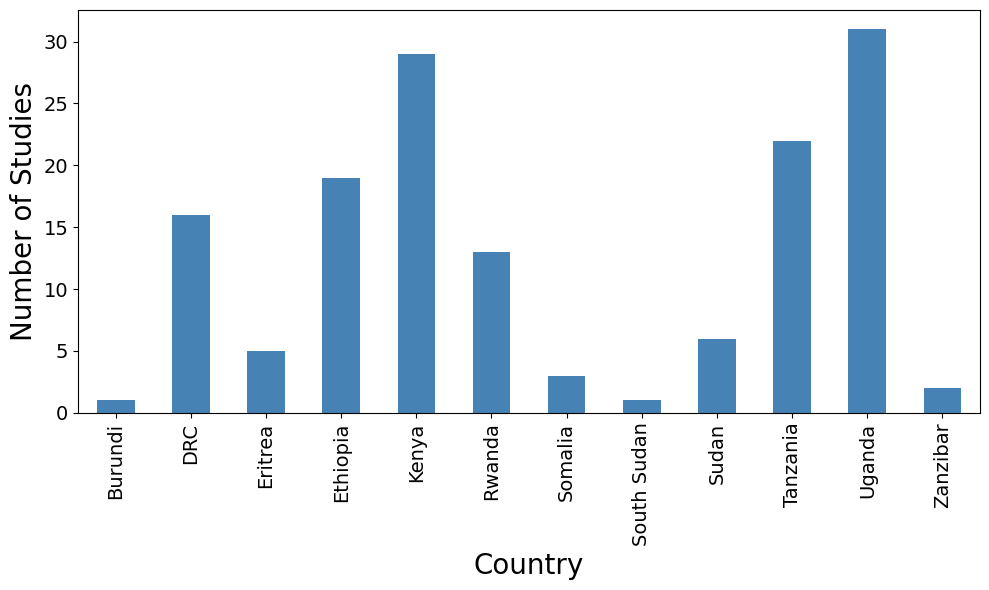

In [8]:
# Plot for studies per country
import matplotlib.pyplot as plt

# Plot
ax = studies_per_country.plot(kind='bar', figsize=(10, 6), color='steelblue')

# Add labels on top of bars
# for i, value in enumerate(studies_per_country):
#    ax.text(i, value + 0.1, str(value), ha='center', va='bottom')

# Customize plot
#plt.title('Number of Studies per Country', fontsize=14)
plt.xlabel('Country', fontsize=20)
plt.ylabel('Number of Studies', fontsize=20)
plt.xticks(rotation=90)
plt.tick_params(axis='both', labelsize=14)
plt.tight_layout()

# Save the plot
#plt.savefig("./version8/studies_per_country_plot1.png", dpi=400, bbox_inches='tight') 
#plt.savefig("./version8/studies_per_country_plot1.pdf") 

# Save as TIFF (required for submission)
#plt.savefig("./version8/studies_per_country_plot1.tif",
#           dpi=400,
#            format="tiff",
#            bbox_inches="tight",
#            pil_kwargs={"compression": "tiff_lzw"})

plt.show()

In [ ]:
# Counting the total number of samples per country
samples_per_country = df.groupby('country')['sample_size'].sum()
print(samples_per_country)

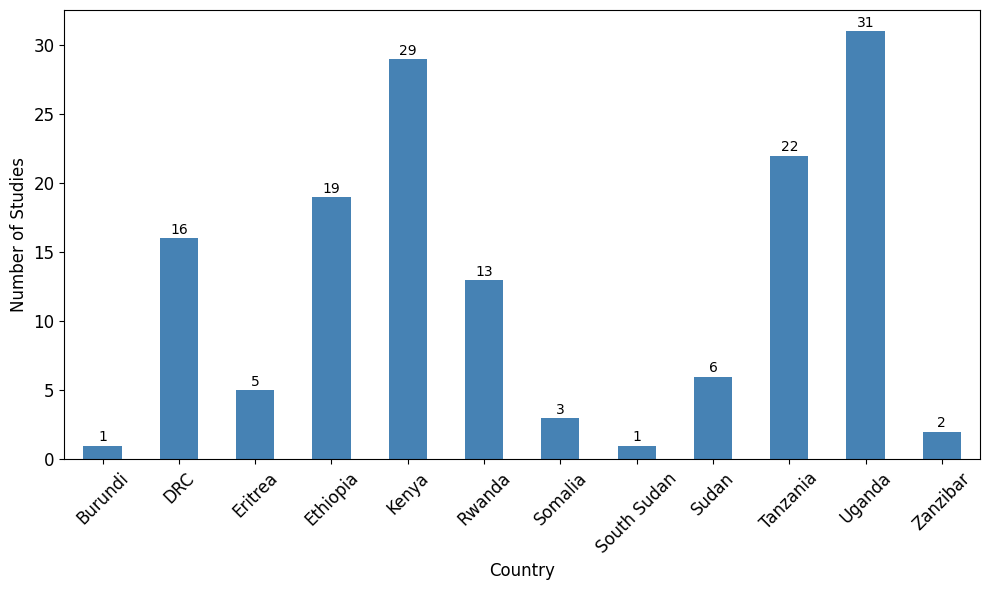

In [10]:
# Plotting number of samples per country

# Plot
ax = studies_per_country.plot(kind='bar', figsize=(10, 6), color='steelblue')

# Add labels on top of bars
for i, value in enumerate(studies_per_country):
    ax.text(i, value + 0.1, str(value), ha='center', va='bottom')

# Customize plot
#plt.title('Number of Studies per Country', fontsize=14)
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Studies', fontsize=12)
plt.xticks(rotation=45)
plt.tick_params(axis='both', labelsize=12)
plt.tight_layout()

# Save the plot
plt.savefig("./version8/studies_per_country_plot_01.png", dpi=400, bbox_inches='tight') 
#plt.savefig("./version8/studies_per_country_plot.pdf") 

plt.savefig("./version8/Supplementary_Figure_1_01.tif",
            dpi=400,
            format="tiff",
           bbox_inches="tight",
          pil_kwargs={"compression": "tiff_lzw"})

plt.show()

In [11]:
import matplotlib.font_manager as fm

fonts = [f.name for f in fm.fontManager.ttflist]
print("Times New Roman" in fonts)

False


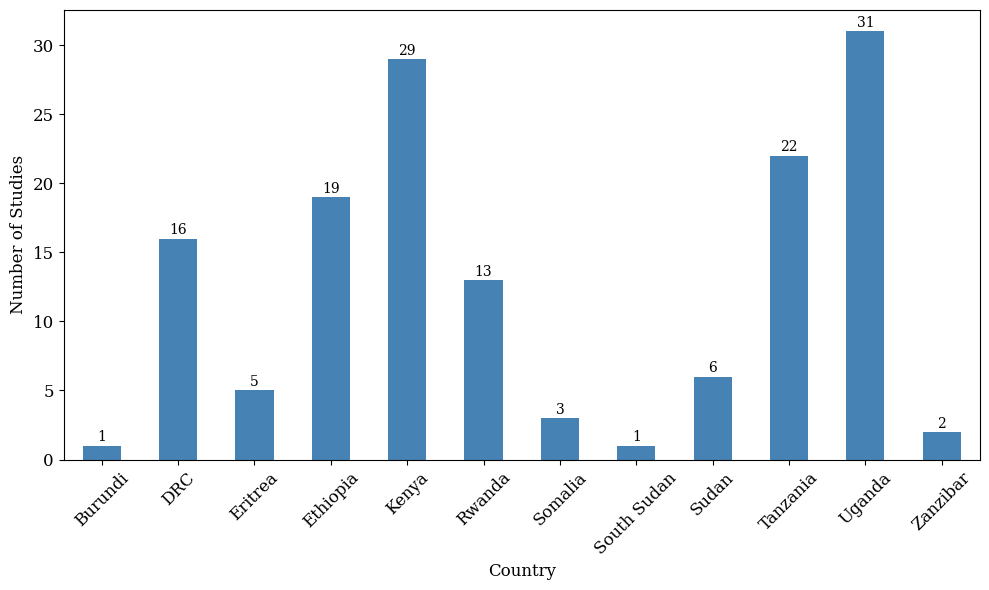

In [13]:
import matplotlib.pyplot as plt

# Set font to Times New Roman
# plt.rcParams.update({
#    "font.family": "serif",
#    "font.serif": ["Times New Roman"]
#})

# Font
plt.rcParams["font.family"] = "DejaVu Serif"

# Plot
ax = studies_per_country.plot(kind='bar', figsize=(10, 6), color='steelblue')

# Add labels on top of bars
for i, value in enumerate(studies_per_country):
    ax.text(i, value + 0.1, str(value), ha='center', va='bottom')

# Labels
plt.xlabel('Country', fontsize=12)
plt.ylabel('Number of Studies', fontsize=12)

# Tick labels
plt.xticks(rotation=45)
plt.tick_params(axis='both', labelsize=12)

plt.tight_layout()

# Save TIFF (journal-ready)
plt.savefig("./version8/Supplementary_Figure_1_times_new_roman3.tif",
            dpi=400,
            format="tiff",
            bbox_inches="tight",
            pil_kwargs={"compression": "tiff_lzw"})

plt.savefig("./version8/Supplementary_Figure_1_times_new_roman3.png", dpi=400, bbox_inches='tight') 
plt.show()

#### Validated mutations per country

In [16]:
import pandas as pd

# Step 1: Ensure correct data types
df["pmid"] = df["pmid"].astype(str)
df["k13_validated_mutations"] = df["k13_validated_mutations"].fillna("").astype(str)
df["country"] = df["country"].fillna("").astype(str)
df["mutation_frequency_(%)"] = df["mutation_frequency_(%)"].astype(str).str.strip()

# Step 2: Define invalid placeholders for mutation
invalid_mutations = {"", "-", ".", "NA", "N/A", "nan", "NaN"}

# Step 3: Build filter for non-zero mutation frequency

# a) Remove values exactly equal to 0, 0.0, 0.000 etc.
mask_not_zero = ~df["mutation_frequency_(%)"].str.fullmatch(r"0+(\.0+)?")

# b) Extract value from parentheses (e.g., from "1/1065 (0.094)")
freq_in_parens = df["mutation_frequency_(%)"].str.extract(r"\(([\d\.]+)\)")
freq_in_parens = pd.to_numeric(freq_in_parens[0], errors="coerce")
mask_parens_gt_zero = freq_in_parens > 0

# Step 4: Keep rows that pass either filter
df = df[mask_not_zero | mask_parens_gt_zero.fillna(False)]

# Step 5: Group by country and summarize
summary_df = df.groupby("country").agg({
    "k13_validated_mutations": lambda x: sorted(set(i.strip() for i in x if i.strip() not in invalid_mutations)),
    "pmid": lambda x: sorted(set(i.strip() for i in x if i.strip() and i.strip().lower() != "nan"))
}).reset_index()

# Step 6: Format results
summary_df["Validated_Mutations"] = summary_df["k13_validated_mutations"].apply(
    lambda x: ", ".join(x) if x else "-"
)
summary_df["Num_Mutations"] = summary_df["k13_validated_mutations"].apply(len)
summary_df["PMIDs"] = summary_df["pmid"].apply(lambda x: ", ".join(x) if x else "-")

# Step 7: Finalize columns
summary_df = summary_df[["country", "Validated_Mutations", "Num_Mutations"]]
summary_df.columns = ["Country", "Validated_Mutations", "Num_Mutations"]

# Step 8: Preview or save
print(summary_df)

# Optional: Save to Excel
#summary_df.to_excel("./version8/validated_mutations_by_country.xlsx", index=False)

    Country                       Validated_Mutations  Num_Mutations
0       DRC                       A675V, C469Y, R561H              3
1   Eritrea                              R561H, R622I              2
2  Ethiopia                A675V, C580Y, P574L, R622I              4
3     Kenya         A675V, C469Y, P553L, R539T, R561H              5
4    Rwanda                A675V, C469Y, P574L, R561H              4
5   Somalia                                     R622I              1
6     Sudan                       C469Y, R561H, R622I              3
7  Tanzania  A675V, C469Y, M476I, P574L, R561H, R622I              6
8    Uganda                A675V, C469Y, P574L, R561H              4
9  Zanzibar                                     R561H              1


In [17]:
df[df["country"]=="Ethiopia"]["k13_validated_mutations"].unique()

array(['R622I', '-', 'C580Y', 'A675V', 'P574L'], dtype=object)

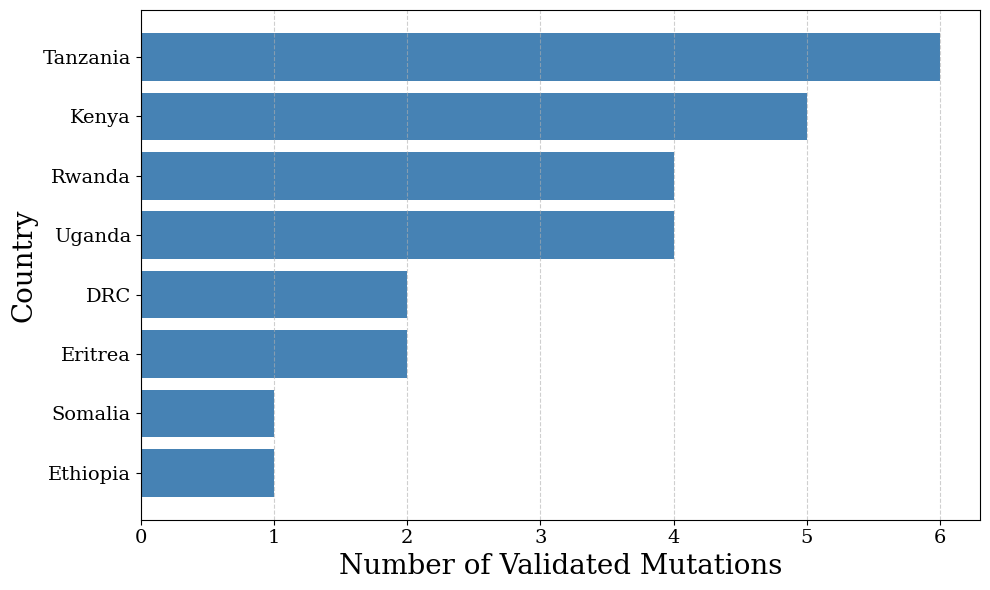

In [18]:
import matplotlib.pyplot as plt
import pandas as pd

# Load data
df1 = pd.read_excel('validated_mutations_by_country.xlsx')

# Drop rows with missing Country or Num_Mutations
df1 = df1.dropna(subset=["Country", "Num_Mutations"])

# Convert 'Country' to string (in case of any numeric types)
df1["Country"] = df1["Country"].astype(str)

# Optional: sort by number of mutations for cleaner presentation
df1 = df1.sort_values("Num_Mutations", ascending=True)

# Create the plot
fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(df1["Country"], df1["Num_Mutations"], color="steelblue")

# Annotate bars with mutation counts
#for bar in bars:
 #   width = bar.get_width()
  #  ax.text(width + 0.1, bar.get_y() + bar.get_height()/2,
   #         str(int(width)), va='center', fontsize=10)

# Aesthetic tweaks
ax.set_xlabel("Number of Validated Mutations", fontsize=20)
#ax.set_title("Validated Mutations by Country", fontsize=14, weight='bold')
ax.grid(axis='x', linestyle='--', alpha=0.6)
#plt.xlabel('Country', fontsize=20)
plt.ylabel('Country', fontsize=20)
#plt.xticks(rotation=45)
plt.tick_params(axis='both', labelsize=14)

plt.tight_layout()
#plt.savefig("./version8/validated_mutations_by_country.png", dpi=400, bbox_inches='tight')
plt.show()

<>:6: SyntaxWarning: invalid escape sequence '\s'
<>:6: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_1636/372228132.py:6: SyntaxWarning: invalid escape sequence '\s'
  df1= df1.assign(Mutation=df1["Validated_Mutations"].str.split(",\s*")).explode("Mutation")


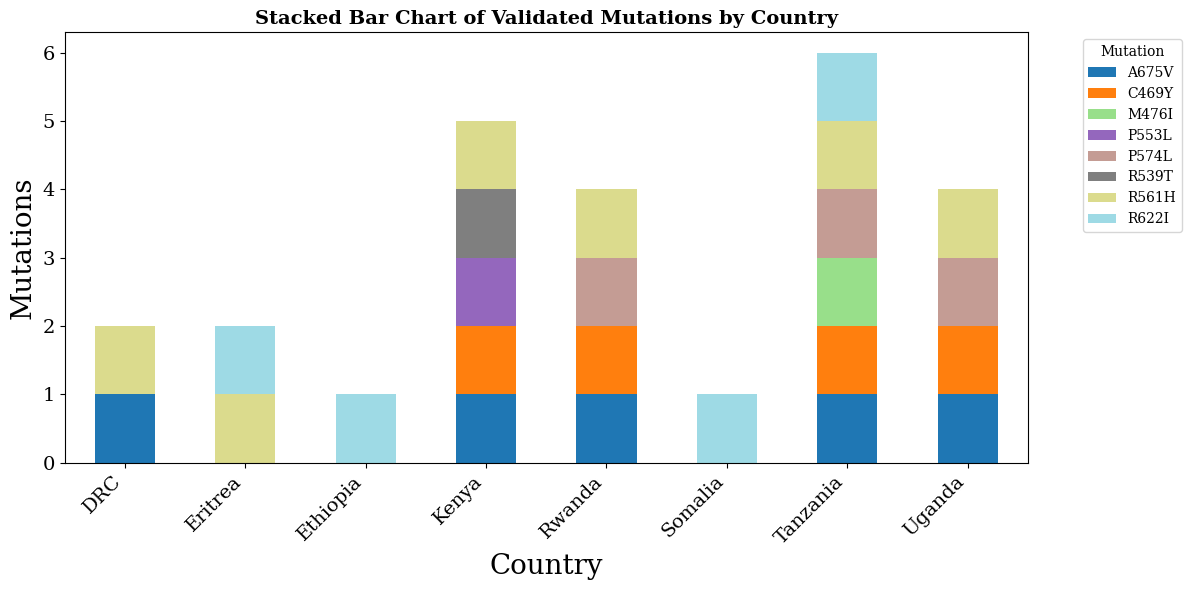

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# Explode mutation list into rows
df1 = df1[df1["Validated_Mutations"] != "-"]  # exclude missing
df1= df1.assign(Mutation=df1["Validated_Mutations"].str.split(",\s*")).explode("Mutation")

# Create pivot: rows = Country, columns = Mutation, values = 1 (presence)
mutation_matrix = df1.pivot_table(index="Country", columns="Mutation",
                                 aggfunc="size", fill_value=0)

# Plot stacked bar chart
mutation_matrix.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="tab20")
plt.title("Stacked Bar Chart of Validated Mutations by Country", fontsize=14, weight='bold')
plt.xlabel("Country", fontsize=20)
plt.ylabel("Mutations", fontsize=20)
plt.xticks(rotation=45, ha="right")
plt.tick_params(axis='both', labelsize=14)
plt.legend(title="Mutation", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
#plt.savefig("./version8/stacked_mutation_bar.png", dpi=400)
plt.show()

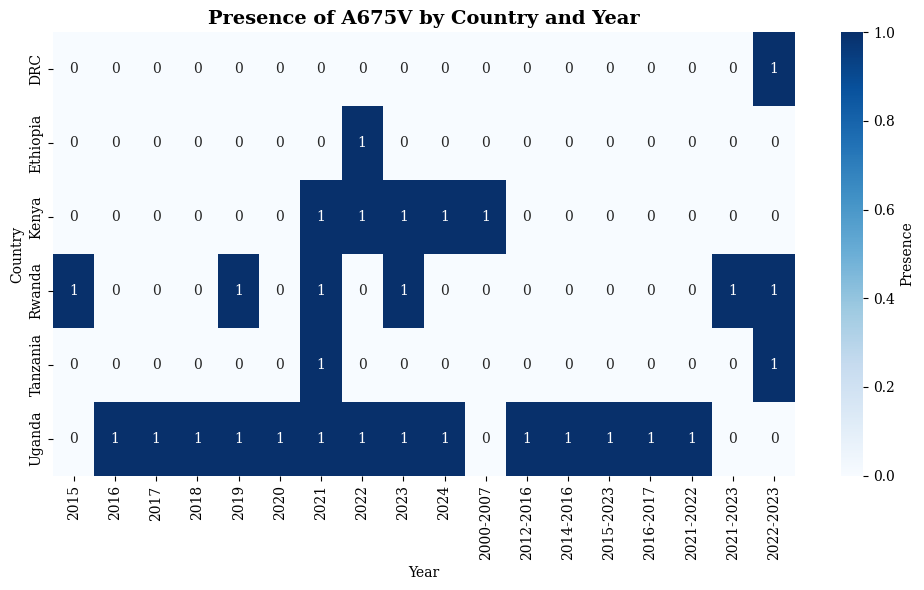

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Filter for a specific mutation, e.g., "A675V"
mutation_of_interest = "A675V"
mutation_df = df[df["k13_validated_mutations"] == mutation_of_interest]

# Create a pivot table: rows = Country, columns = Year, values = presence (1)
heatmap_data = mutation_df.assign(presence=1).pivot_table(
    index="country",
    columns="year_sample",
    values="presence",
    fill_value=0
)

# Plot the heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(heatmap_data, annot=True, cmap="Blues", cbar_kws={'label': 'Presence'})
plt.title(f"Presence of {mutation_of_interest} by Country and Year", fontsize=14, weight='bold')
plt.xlabel("Year")
plt.ylabel("Country")
plt.tight_layout()
#plt.savefig(f"{mutation_of_interest}_presence_heatmap.png", dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt

mutation_of_interest = "A675V"
mutation_df = df[df["k13_validated_mutations"] == mutation_of_interest]

plt.figure(figsize=(10, 6))
plt.scatter(mutation_df["year_sample"], mutation_df["country"], color="blue", s=100)
plt.title(f"Timeline of {mutation_of_interest} Detection", fontsize=14, weight='bold')
plt.xlabel("Year")
plt.ylabel("Country")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
#plt.savefig(f"{mutation_of_interest}_timeline.png", dpi=300)
plt.show()


In [22]:
import pandas as pd

# Step 1: Copy and format columns
df2 = df.copy()
df2["k13_validated_mutations"] = df2["k13_validated_mutations"].fillna("").astype(str)
df2["mutation_frequency_(%)"] = df2["mutation_frequency_(%)"].astype(str).str.strip()
df2["country"] = df2["country"].fillna("").astype(str).str.strip()
df2["year_pub"] = pd.to_numeric(df2["year_pub"], errors="coerce")

# Step 2: Filter out invalid mutation entries
invalid_mutations = {"", "-", ".", "NA", "N/A", "nan", "NaN"}

# Step 3: Filter mutation frequency > 0
# a) Drop rows that are exactly zero
mask_not_zero = ~df2["mutation_frequency_(%)"].str.fullmatch(r"0+(\.0+)?")

# b) Also include frequencies like (0.094) in strings like "1/1065 (0.094)"
freq_in_parens = df2["mutation_frequency_(%)"].str.extract(r"\(([\d\.]+)\)")
freq_in_parens = pd.to_numeric(freq_in_parens[0], errors="coerce")
mask_parens_gt_zero = freq_in_parens > 0

# Apply combined filter
df2 = df2[mask_not_zero | mask_parens_gt_zero.fillna(False)]

# Step 4: Drop rows where mutation field is still invalid
df2 = df2[~df2["k13_validated_mutations"].isin(invalid_mutations)]

# Step 5: Explode mutations into rows
df2 = df2.assign(Mutation=df2["k13_validated_mutations"].str.split(r",\s*")).explode("Mutation")

# Step 6: Clean up Mutation and Country
df2["Mutation"] = df2["Mutation"].str.strip().str.upper()
df2["country"] = df2["country"].str.strip()  # Optionally .str.title()

# Step 7: Keep only rows with valid year
df2 = df2.dropna(subset=["year_pub"])
df2["year_pub"] = df2["year_pub"].astype(int)

# Step 8: Get first year each mutation appeared by country
first_seen = df2.groupby(["country", "Mutation"])["year_pub"].min().reset_index()

# Preview
print(first_seen.head())

   country Mutation  year_pub
0      DRC    A675V      2024
1      DRC    C469Y      2024
2      DRC    R561H      2024
3  Eritrea    R561H      2023
4  Eritrea    R622I      2020


In [23]:
# Ensure the country column is properly formatted
df2["country"] = df2["country"].str.strip() #str.title()

# Filter for a country and check unique mutations
Ethiopia_mutations = df2[df2["country"] == "Ethiopia"]["k13_validated_mutations"].str.strip().unique()
print(Ethiopia_mutations)

['R622I' 'C580Y' 'A675V' 'P574L']


In [24]:
print(first_seen.sort_values(["Mutation", "country"]).to_string(index=False))

 country Mutation  year_pub
     DRC    A675V      2024
Ethiopia    A675V      2025
   Kenya    A675V      2023
  Rwanda    A675V      2016
Tanzania    A675V      2023
  Uganda    A675V      2018
     DRC    C469Y      2024
   Kenya    C469Y      2024
  Rwanda    C469Y      2020
   Sudan    C469Y      2023
Tanzania    C469Y      2024
  Uganda    C469Y      2018
Ethiopia    C580Y      2025
Tanzania    M476I      2021
   Kenya    P553L      2014
Ethiopia    P574L      2025
  Rwanda    P574L      2016
Tanzania    P574L      2024
  Uganda    P574L      2019
   Kenya    R539T      2023
     DRC    R561H      2024
 Eritrea    R561H      2023
   Kenya    R561H      2023
  Rwanda    R561H      2020
   Sudan    R561H      2023
Tanzania    R561H      2020
  Uganda    R561H      2023
Zanzibar    R561H      2025
 Eritrea    R622I      2020
Ethiopia    R622I      2015
 Somalia    R622I      2019
   Sudan    R622I      2023
Tanzania    R622I      2023


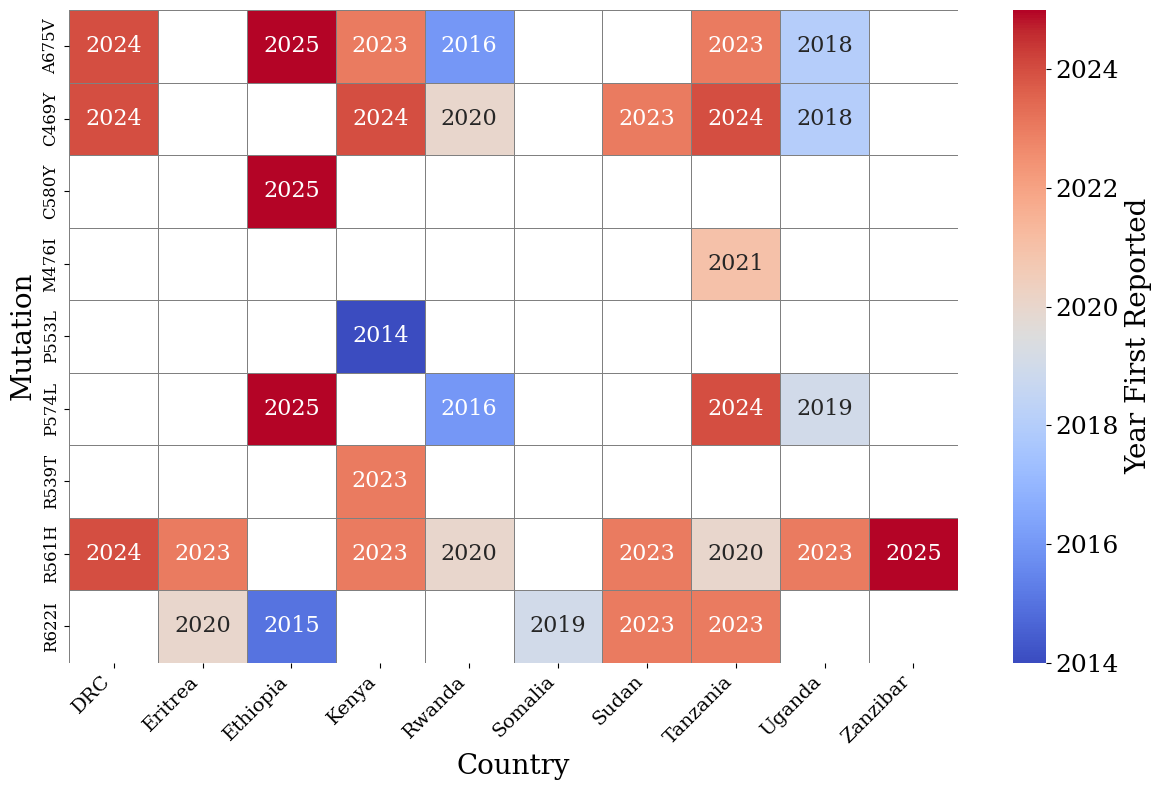

In [25]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot for heatmap
heatmap_data = first_seen.pivot(index="Mutation", columns="country", values="year_pub")

# Mask missing values
mask = heatmap_data.isna()

# Plot
plt.figure(figsize=(12, 8))

ax = sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap="coolwarm", mask=mask, linewidths=0.5, linecolor='gray', annot_kws={"size": 16}, cbar_kws={"label": "Year First Reported"})

# Axis labels
plt.xlabel("Country", fontsize=20)
plt.ylabel("Mutation", fontsize=20)

# Tick labels
plt.xticks(fontsize=14, rotation=45, ha='right')  # 🔥 improves readability
plt.yticks(fontsize=12)

# Colorbar (legend)
cbar = ax.figure.axes[-1]
cbar.tick_params(labelsize=18)
cbar.set_ylabel("Year First Reported", fontsize=20)

# Clean look (optional but recommended)
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
#plt.savefig("./version7/first_reported_mutation_heatmap.png", dpi=400)
plt.show()

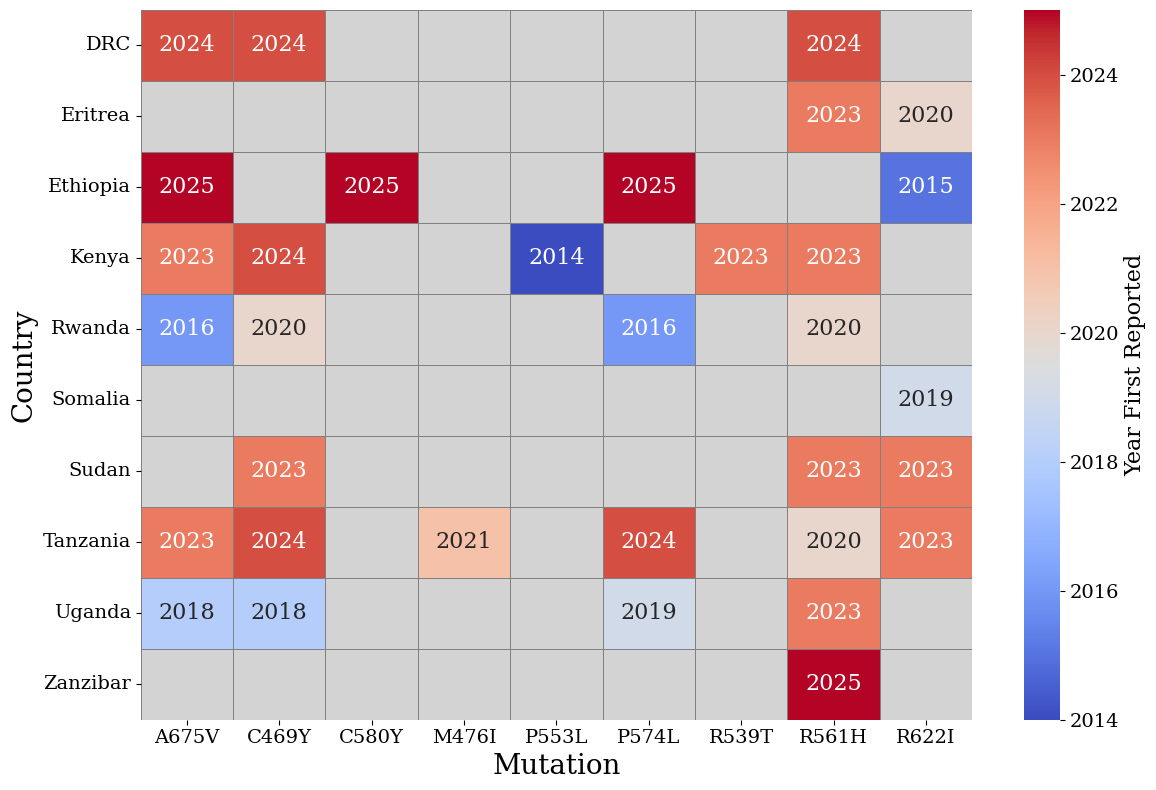

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot
heatmap_data = first_seen.pivot(index="country", columns="Mutation", values="year_pub")

# Optional: mask missing values (keeps them blank instead of misleading)
mask = heatmap_data.isna()

# Better colormap (handles NaNs nicely)
cmap = sns.color_palette("coolwarm", as_cmap=True)
cmap.set_bad(color="lightgrey")  # missing = grey

# Plot
plt.figure(figsize=(12, 8))  # slightly wider for readability

ax = sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap=cmap, mask=mask, linewidths=0.5, linecolor='gray', annot_kws={"size": 16}, cbar_kws={"label": "Year First Reported"})

# Axis labels
plt.xlabel("Mutation", fontsize=20)
plt.ylabel("Country", fontsize=20)

# Tick formatting
plt.xticks(fontsize=14)
plt.yticks(rotation=0, fontsize=14)

# Colorbar (legend) improvement
cbar = ax.figure.axes[-1]
cbar.tick_params(labelsize=14)
cbar.set_ylabel("Year First Reported", fontsize=16)

# Remove top/right spines for cleaner look
for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
#plt.savefig("./version7/first_reported_mutation_heatmap1_grey.png", dpi=400)
plt.show()

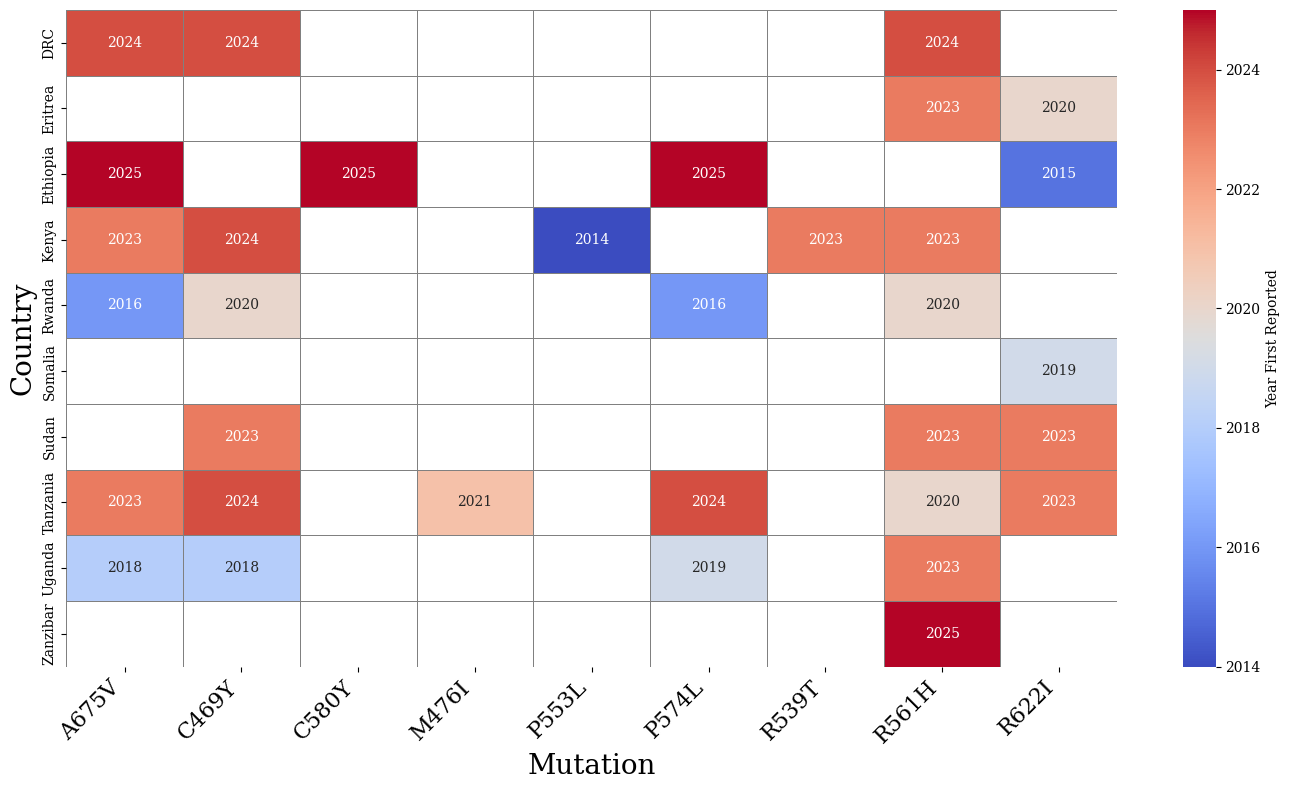

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot with countries on y-axis and mutations on x-axis
heatmap_data = first_seen.pivot(index="country", columns="Mutation", values="year_pub")

# Plot
plt.figure(figsize=(14, 8))  # Wider for many mutations
sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="coolwarm",
    cbar_kws={"label": "Year First Reported"},
    linewidths=0.5,
    linecolor='gray'
)

#plt.title("First Year Each Validated Mutation Was Reported by Country", fontsize=14, weight='bold')
plt.xlabel("Mutation", fontsize=20)
plt.ylabel("Country", fontsize=20)
plt.xticks(rotation=45, ha="right", fontsize=16)
plt.tight_layout()
#plt.savefig("./version7/first_reported_mutation_heatmap2.png", dpi=400)
plt.show()

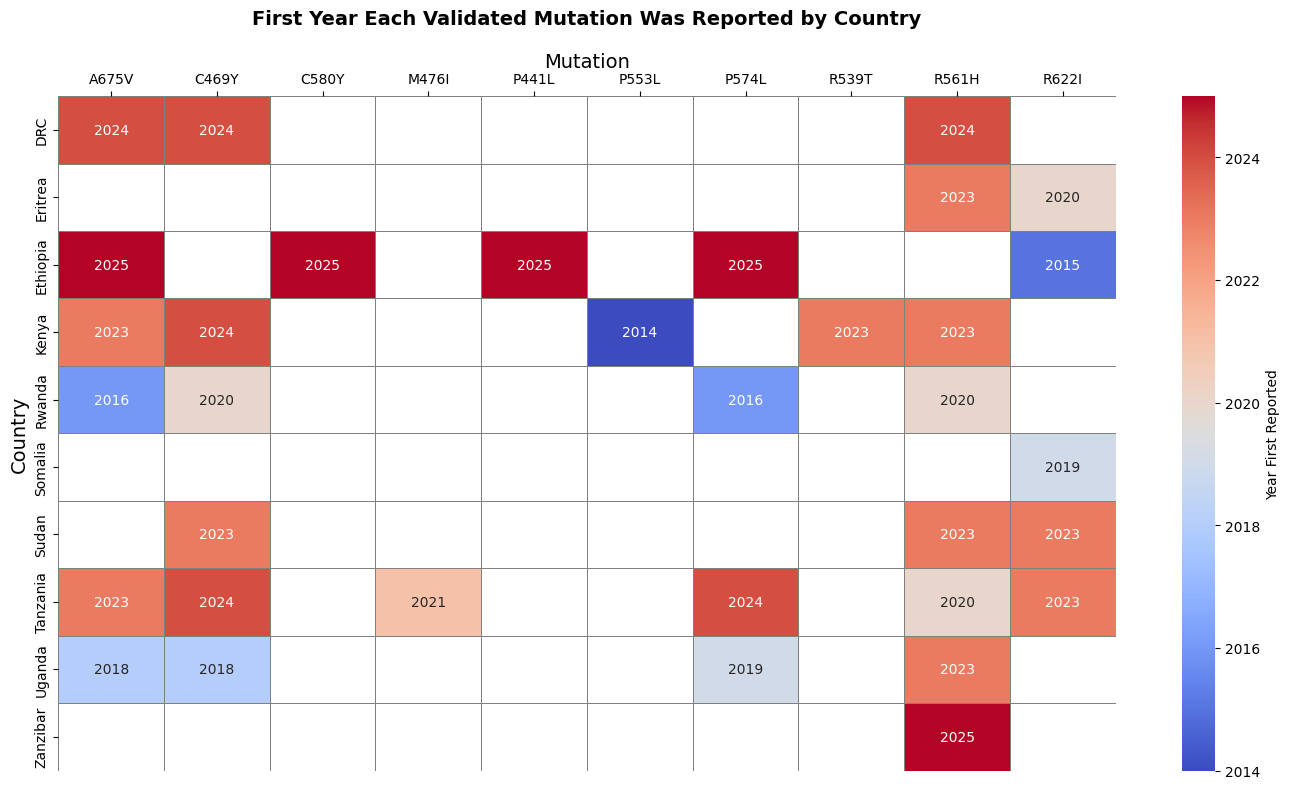

In [30]:
import seaborn as sns
import matplotlib.pyplot as plt

# Pivot: countries on y-axis, mutations on x-axis
heatmap_data = first_seen.pivot(index="country", columns="Mutation", values="year_pub")

# Plot
plt.figure(figsize=(14, 8))
ax = sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".0f",
    cmap="coolwarm",
    cbar_kws={"label": "Year First Reported"},
    linewidths=0.5,
    linecolor='gray'
)

# Set labels and position mutations (x-axis) on top
ax.set_title("First Year Each Validated Mutation Was Reported by Country", fontsize=14, weight='bold', pad=20)
ax.set_xlabel("Mutation", fontsize=14)
ax.set_ylabel("Country", fontsize=14)
#ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="left")

# Move x-axis to top
ax.xaxis.set_ticks_position("top")
ax.xaxis.set_label_position("top")

plt.tight_layout()
#plt.savefig("./version7/first_reported_mutation_heatmap3.png", dpi=400)

plt.show()

## Fisrt year mutation was sampled

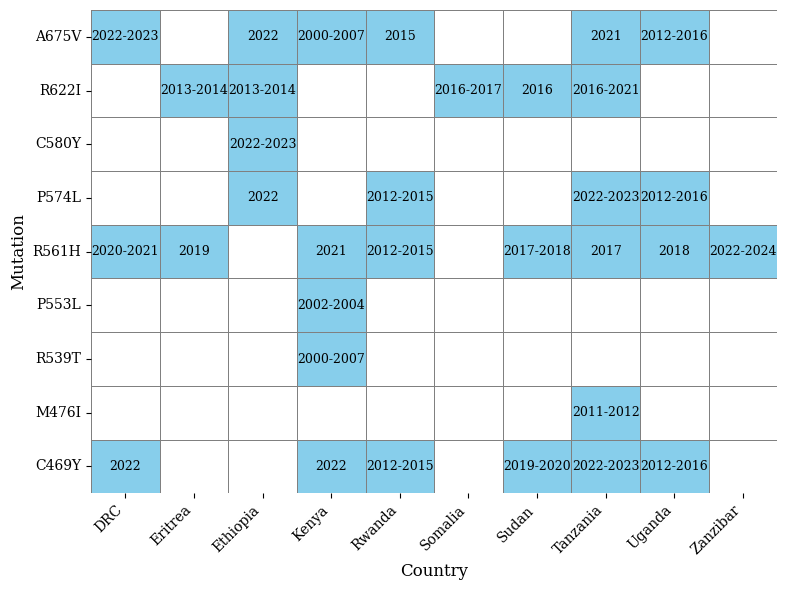

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import re

# Step 1: Ensure year_sample is string
df2["year_sample"] = df2["year_sample"].astype(str).str.strip()

# Step 2: Extract start and end years
year_pairs = df2["year_sample"].str.extract(r"(?P<start_year>\d{4})\D+(?P<end_year>\d{4})")
single_year = df2["year_sample"].str.extract(r"(?P<year>\d{4})")
year_pairs["start_year"] = year_pairs["start_year"].combine_first(single_year["year"])
year_pairs["end_year"] = year_pairs["end_year"].combine_first(single_year["year"])

# Step 3: Convert to numeric
year_pairs = year_pairs.apply(pd.to_numeric, errors="coerce")

# Step 4: Add back to original DataFrame
df2["start_year"] = year_pairs["start_year"]
df2["end_year"] = year_pairs["end_year"]

# Step 5: Construct a clean year range label
df2["year_range_label"] = df2.apply(
    lambda row: f"{int(row['start_year'])}-{int(row['end_year'])}" if pd.notnull(row["start_year"]) and pd.notnull(row["end_year"]) and row["start_year"] != row["end_year"]
    else f"{int(row['start_year'])}" if pd.notnull(row["start_year"])
    else "Unknown", axis=1
)

# Step 6: Group by country and mutation, pick earliest start year and year label
first_seen = df2.groupby(["country", "Mutation"]).agg({
    "start_year": "min",
    "year_range_label": lambda x: sorted(set(x))[0]
}).reset_index()

# Step 7: Extract numeric part from mutation (e.g., C469Y -> 469)
first_seen["mutation_number"] = first_seen["Mutation"].str.extract(r"(\d+)").astype(int)

# Step 8: Sort data
first_seen_sorted = first_seen.sort_values(
    by=["mutation_number", "country"],
    ascending=[True, True]
)

# Step 9: Pivot (SWITCH AXES)
# Mutations on Y-axis, Countries on X-axis
heatmap_data = first_seen_sorted.pivot(
    index="Mutation",      # Y-axis
    columns="country",     # X-axis
    values="year_range_label"
)

# Step 10: Sort countries alphabetically (X-axis)
heatmap_data = heatmap_data.reindex(sorted(heatmap_data.columns), axis=1)

# Step 11: Sort mutations by numeric part (Y-axis)
mutation_order = (
    first_seen_sorted
    .drop_duplicates("Mutation")
    .sort_values("mutation_number")["Mutation"]
)

heatmap_data = heatmap_data.reindex(mutation_order, axis=0)

# Reverse mutation order: smallest at bottom
mutation_order_reversed = mutation_order[::-1]

heatmap_data = heatmap_data.reindex(mutation_order_reversed, axis=0)

# Binary matrix
binary_matrix = heatmap_data.notna().astype(int)

# Annotation matrix
annot_data = heatmap_data.fillna("")

# Plot (smaller size)
plt.figure(figsize=(8, 6))

sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.4,
    linecolor="gray",
    annot_kws={
        "fontsize": 9,
        "color": "black",
        "ha": "center",
        "va": "center"
    }
)

# No title

plt.xlabel("Country", fontsize=12)
plt.ylabel("Mutation", fontsize=12)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()

#plt.savefig("./version8/first_sampled_mutation_heatmap_newest.png", dpi=400)
plt.show()


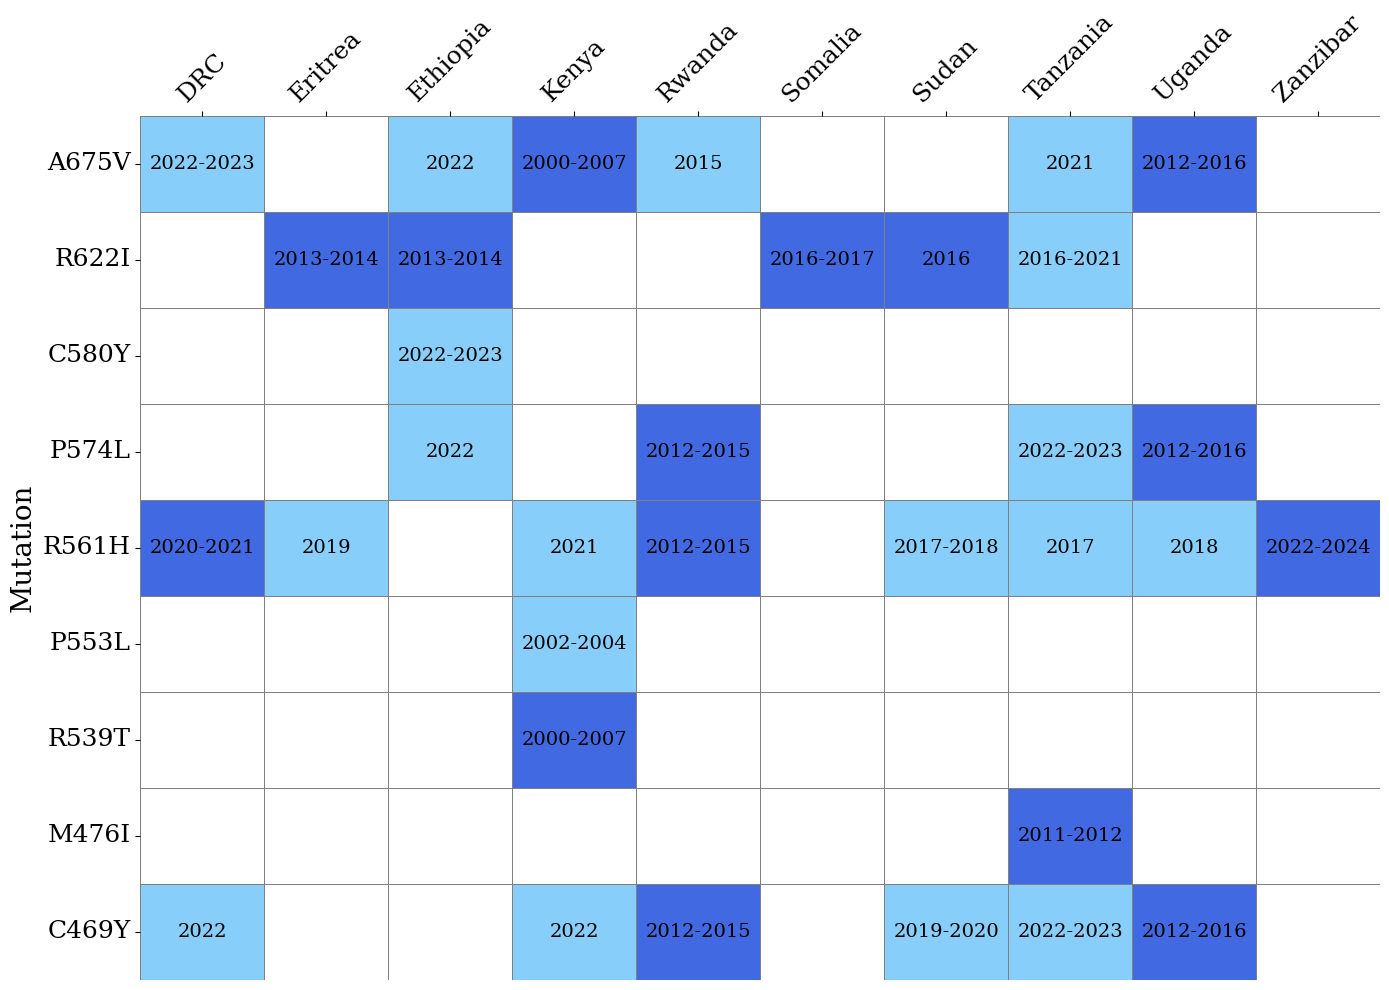

In [29]:
import numpy as np
# --------------------------------------------------
# STEP 12: Create numeric year matrix for coloring
# --------------------------------------------------

# Extract numeric year from annotation (e.g. "2004-2006" -> 2004)
year_numeric = heatmap_data.map(
    lambda x: int(str(x).split("-")[0]) if pd.notnull(x) and x != "" else None
)

# --------------------------------------------------
# STEP 13: Build color matrix
# 0 = no data
# 1 = present
# 2 = earliest in country
# --------------------------------------------------

color_matrix = pd.DataFrame(
    0,
    index=year_numeric.index,
    columns=year_numeric.columns
)

for country in year_numeric.columns:

    col_data = year_numeric[country]

    if col_data.notna().any():

        earliest = col_data.min()

        for mutation in col_data.index:

            if pd.isna(col_data.loc[mutation]):
                color_matrix.loc[mutation, country] = 0

            elif col_data.loc[mutation] == earliest:
                color_matrix.loc[mutation, country] = 2   # darkest

            else:
                color_matrix.loc[mutation, country] = 1   # normal


# --------------------------------------------------
# STEP 14: Custom colormap (white → light → dark)
# --------------------------------------------------

custom_cmap = sns.color_palette(
    ["white", "lightskyblue", "royalblue"]
)


# --------------------------------------------------
# STEP 15: Plot
# --------------------------------------------------

plt.figure(figsize=(14, 10))

sns.heatmap(
    color_matrix,
    annot=annot_data,
    fmt="",
    cmap=custom_cmap,
    cbar=False,
    linewidths=0.4,
    linecolor="gray",
    vmin=0,
    vmax=2,
    #square=True,
    annot_kws={
        "fontsize": 14,
        "color": "black",
        "ha": "center",
        "va": "center"
    }
)

ax = plt.gca()
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

#plt.xlabel("Country", fontsize=20)
ax.set_xlabel("")
plt.ylabel("Mutation", fontsize=20)

plt.xticks(rotation=45, fontsize=18)
plt.yticks(rotation=0, fontsize=18)

plt.tight_layout()

#plt.savefig("./version7/first_sampled_mutation_heatmap_newest2.png", dpi=400)
plt.show()

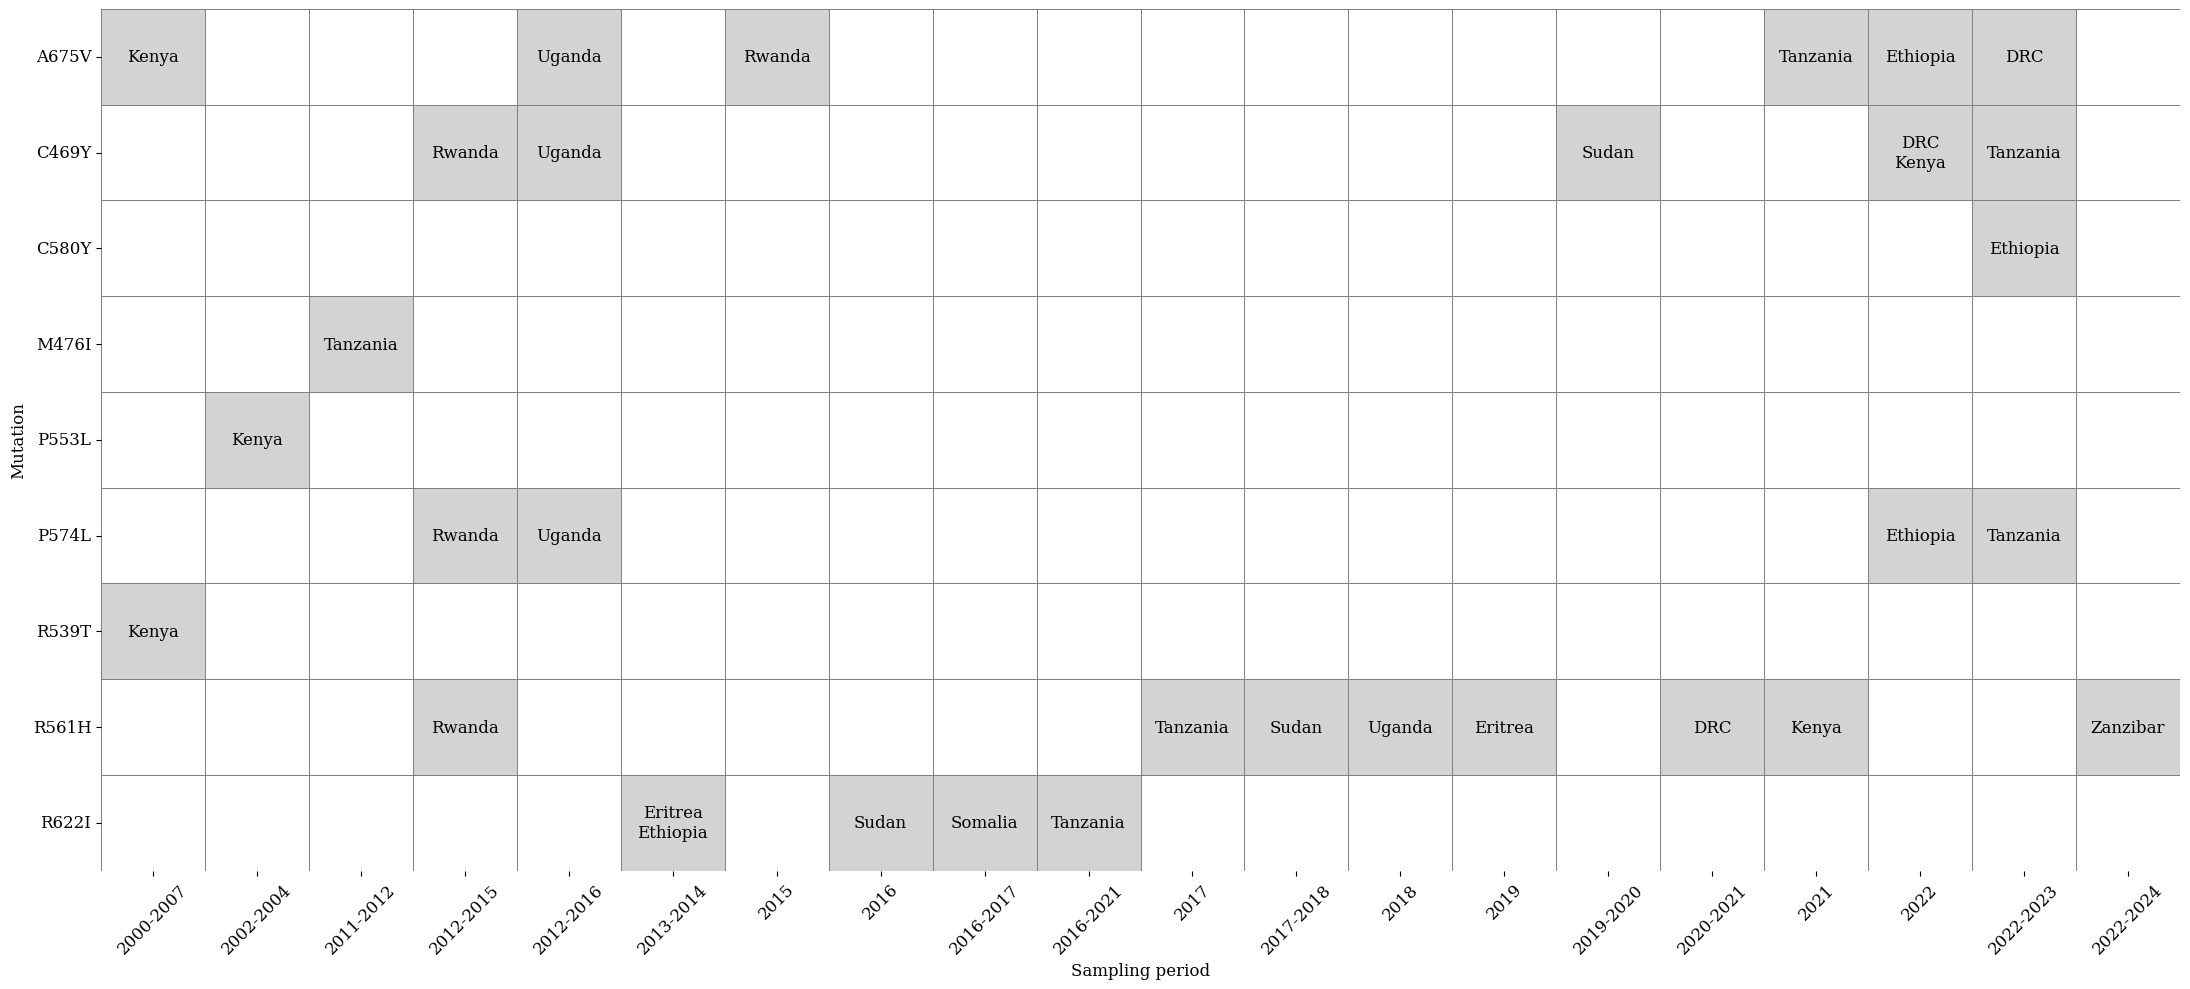

In [30]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Convert wide → long
# --------------------------------------------------

df_long = heatmap_data.reset_index().melt(
    id_vars=heatmap_data.index.name or "mutation",
    var_name="country",
    value_name="year"
)

df_long = df_long.rename(columns={df_long.columns[0]: "mutation"})

# Keep year strings exactly (including ranges)
df_long["year_clean"] = df_long["year"]

# Remove empty values
df_long = df_long[df_long["year_clean"].notna() & (df_long["year_clean"] != "")]

# --------------------------------------------------
# STEP 2: Pivot → mutation × year, values = countries
# --------------------------------------------------

heatmap_year_country = df_long.pivot_table(
    index="mutation",
    columns="year_clean",
    values="country",
    aggfunc=lambda x: "\n".join(sorted(set(x)))  # 🔥 vertical stacking
)

# --------------------------------------------------
# STEP 3: Annotation matrix (remove NaNs)
# --------------------------------------------------

annot_matrix = heatmap_year_country.fillna("")

# --------------------------------------------------
# STEP 4: Color matrix (presence only)
# --------------------------------------------------

color_matrix = heatmap_year_country.notna().astype(int)

# --------------------------------------------------
# STEP 5: Optional — sort years chronologically
# (handles ranges like "2000-2007")
# --------------------------------------------------

def extract_year_start(x):
    try:
        return int(str(x).split("-")[0])
    except:
        return 9999

sorted_cols = sorted(heatmap_year_country.columns, key=extract_year_start)

heatmap_year_country = heatmap_year_country[sorted_cols]
annot_matrix = annot_matrix[sorted_cols]
color_matrix = color_matrix[sorted_cols]

# --------------------------------------------------
# STEP 6: Plot
# --------------------------------------------------

custom_cmap = sns.color_palette(["white", "lightgray"])

plt.figure(figsize=(22, 10))

sns.heatmap(
    color_matrix,
    annot=annot_matrix,
    fmt="",
    cmap=custom_cmap,
    cbar=False,
    linewidths=0.4,
    linecolor="gray",
    annot_kws={
        "fontsize": 12,
        "color": "black",
        "ha": "center",
        "va": "center"
    }
)

# Axis formatting
ax = plt.gca()
ax.xaxis.tick_bottom()
ax.xaxis.set_label_position('bottom')

plt.xlabel("Sampling period", fontsize=12)
plt.ylabel("Mutation", fontsize=12)

plt.xticks(rotation=45, ha="center", fontsize=12)
plt.yticks(rotation=0, fontsize=12)

plt.tight_layout()

# save as pdf
#plt.savefig("./version8/final_spatiotemporal_heatmap_periods.pdf") 
# Save TIFF (journal-ready)
#plt.savefig("./version8/Figure_3_12.tif",
 #           dpi=300,
  #          format="tiff",
   #         bbox_inches="tight",
    #        pil_kwargs={"compression": "tiff_lzw"})

plt.show()
# Save if needed
#plt.savefig("./version8/final_spatiotemporal_heatmap_periods.png", dpi=400, bbox_inches="tight")

#plt.show()

Countries and assigned colours:
DRC (0.12156862745098039, 0.4666666666666667, 0.7058823529411765)
Eritrea (0.6823529411764706, 0.7803921568627451, 0.9098039215686274)
Ethiopia (1.0, 0.4980392156862745, 0.054901960784313725)
Kenya (1.0, 0.7333333333333333, 0.47058823529411764)
Rwanda (0.17254901960784313, 0.6274509803921569, 0.17254901960784313)
Somalia (0.596078431372549, 0.8745098039215686, 0.5411764705882353)
Sudan (0.8392156862745098, 0.15294117647058825, 0.1568627450980392)
Tanzania (1.0, 0.596078431372549, 0.5882352941176471)
Uganda (0.5803921568627451, 0.403921568627451, 0.7411764705882353)
Zanzibar (0.7725490196078432, 0.6901960784313725, 0.8352941176470589)


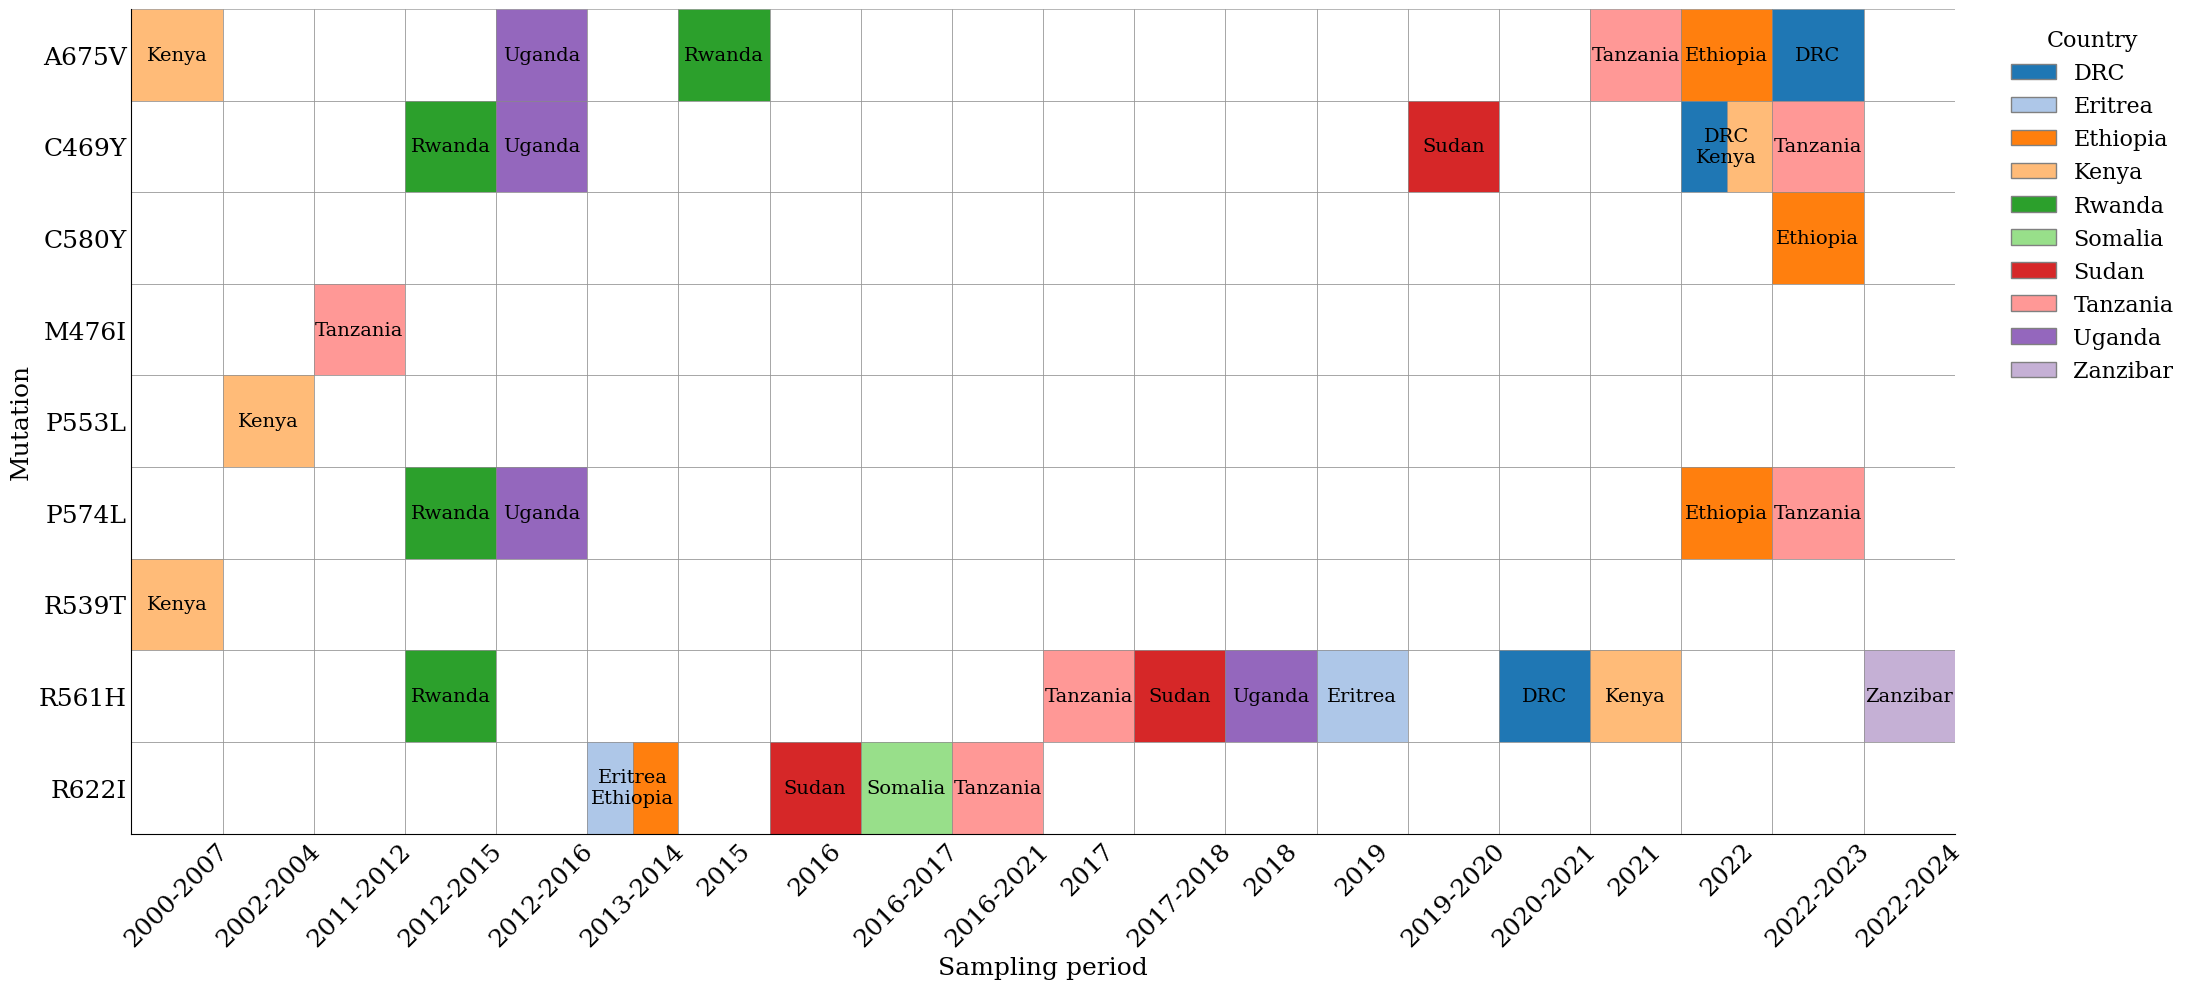

In [33]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# --------------------------------------------------
# STEP 1: Convert wide → long
# --------------------------------------------------

df_long = heatmap_data.reset_index().melt(
    id_vars=heatmap_data.index.name or "mutation",
    var_name="country",
    value_name="year"
)

df_long = df_long.rename(columns={df_long.columns[0]: "mutation"})

# Keep year strings exactly (including ranges)
df_long["year_clean"] = df_long["year"]

# Remove empty values
df_long = df_long[
    df_long["year_clean"].notna() &
    (df_long["year_clean"] != "")
]

# --------------------------------------------------
# STEP 2: Create country colour mapping
# --------------------------------------------------

countries = sorted(df_long["country"].unique())

# Use a distinct palette
palette = sns.color_palette("tab20", n_colors=len(countries))

country_colors = dict(zip(countries, palette))

print("Countries and assigned colours:")
for country, color in country_colors.items():
    print(country, color)

# --------------------------------------------------
# STEP 3: Pivot → mutation × year
# Values = countries
# --------------------------------------------------

heatmap_year_country = df_long.pivot_table(
    index="mutation",
    columns="year_clean",
    values="country",
    aggfunc=lambda x: "\n".join(sorted(set(x)))
)

# --------------------------------------------------
# STEP 4: Annotation matrix
# --------------------------------------------------

annot_matrix = heatmap_year_country.fillna("")

# --------------------------------------------------
# STEP 5: Sort years chronologically
# --------------------------------------------------

def extract_year_start(x):
    try:
        return int(str(x).split("-")[0])
    except:
        return 9999

sorted_cols = sorted(
    heatmap_year_country.columns,
    key=extract_year_start
)

heatmap_year_country = heatmap_year_country[sorted_cols]
annot_matrix = annot_matrix[sorted_cols]

# --------------------------------------------------
# STEP 6: Create figure
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(22, 10))

# Number of rows and columns
n_rows = len(heatmap_year_country.index)
n_cols = len(heatmap_year_country.columns)

# --------------------------------------------------
# STEP 7: Draw cells
# --------------------------------------------------

for i, mutation in enumerate(heatmap_year_country.index):

    for j, period in enumerate(heatmap_year_country.columns):

        value = heatmap_year_country.loc[mutation, period]

        # Empty cell
        if pd.isna(value) or value == "":
            ax.add_patch(
                Rectangle(
                    (j, i),
                    1,
                    1,
                    facecolor="white",
                    edgecolor="gray",
                    linewidth=0.4
                )
            )

        else:

            # Get countries in this cell
            cell_countries = [
                c.strip()
                for c in str(value).split("\n")
                if c.strip()
            ]

            n_cell_countries = len(cell_countries)

            # --------------------------------------------------
            # Split cell vertically according to number of countries
            # --------------------------------------------------

            section_width = 1 / n_cell_countries

            for k, country in enumerate(cell_countries):

                x_position = j + k * section_width

                ax.add_patch(
                    Rectangle(
                        (x_position, i),
                        section_width,
                        1,
                        facecolor=country_colors[country],
                        edgecolor="gray",
                        linewidth=0.4
                    )
                )

# --------------------------------------------------
# STEP 8: Add country names
# --------------------------------------------------

for i, mutation in enumerate(heatmap_year_country.index):

    for j, period in enumerate(heatmap_year_country.columns):

        value = heatmap_year_country.loc[mutation, period]

        if pd.notna(value) and value != "":

            ax.text(
                j + 0.5,
                i + 0.5,
                value,
                ha="center",
                va="center",
                fontsize=14,
                color="black",
                zorder=10
            )

# --------------------------------------------------
# STEP 9: Axis formatting
# --------------------------------------------------

ax.set_xlim(0, n_cols)
ax.set_ylim(n_rows, 0)

ax.set_xticks(np.arange(n_cols) + 0.5)
ax.set_yticks(np.arange(n_rows) + 0.5)

ax.set_xticklabels(
    heatmap_year_country.columns,
    rotation=45,
    ha="center",
    fontsize=18
)

ax.set_yticklabels(
    heatmap_year_country.index,
    rotation=0,
    fontsize=18
)

ax.set_xlabel(
    "Sampling period",
    fontsize=18
)

ax.set_ylabel(
    "Mutation",
    fontsize=18
)

# --------------------------------------------------
# STEP 10: Country legend
# --------------------------------------------------

legend_handles = [
    Patch(
        facecolor=country_colors[country],
        edgecolor="gray",
        label=country
    )
    for country in countries
]

ax.legend(
    handles=legend_handles,
    title="Country",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    frameon=False,
    fontsize=16,
    title_fontsize=16
)

# --------------------------------------------------
# STEP 11: Clean appearance
# --------------------------------------------------

ax.tick_params(
    axis="both",
    which="both",
    length=0
)

sns.despine(
    ax=ax,
    left=False,
    bottom=False
)

plt.tight_layout()

# --------------------------------------------------
# STEP 12: Save as PDF
# --------------------------------------------------

plt.savefig(
    "./version8/final_spatiotemporal_heatmap_periods_colored.pdf",
    bbox_inches="tight"
)

# --------------------------------------------------
# Optional: save TIFF
# --------------------------------------------------

# plt.savefig(
#     "./version8/Figure_3_12_colored.tif",
#     dpi=300,
#     format="tiff",
#     bbox_inches="tight",
#     pil_kwargs={"compression": "tiff_lzw"}
# )
# plt.savefig("./version8/final_spatiotemporal_heatmap_periods_colored.png", dpi=400, bbox_inches="tight")
plt.show()

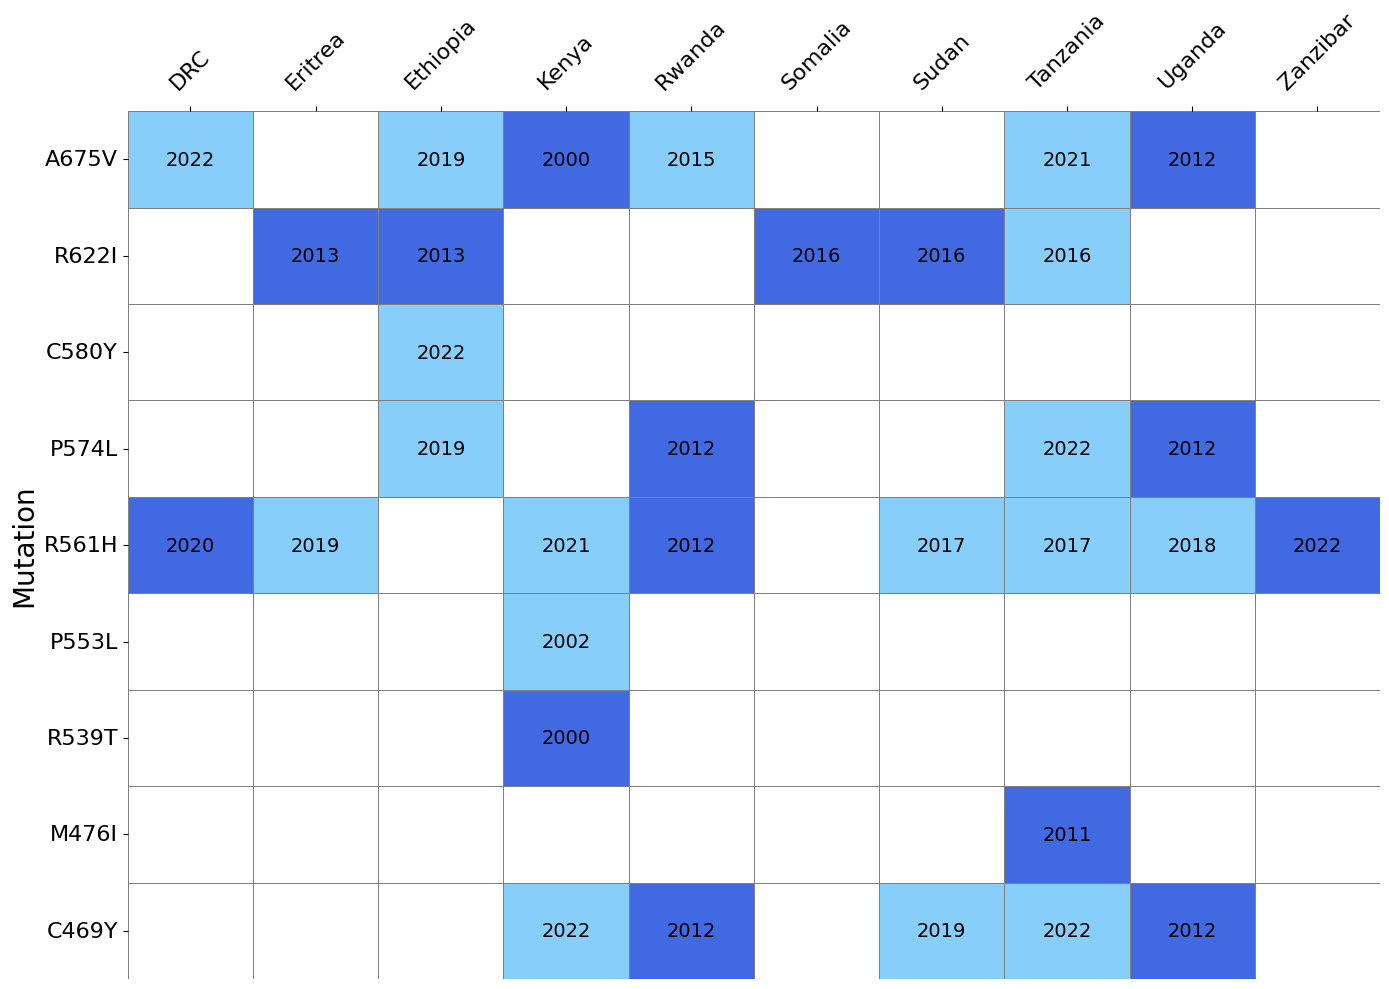

In [41]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 12: Extract earliest year (for BOTH color + annotation)
# --------------------------------------------------

def extract_year(x):
    if pd.notnull(x) and x != "":
        return int(str(x).split("-")[0])
    return np.nan

year_numeric = heatmap_data.map(extract_year)

# Clean annotation (display only earliest year)
annot_clean = heatmap_data.map(
    lambda x: str(x).split("-")[0] if pd.notnull(x) and x != "" else ""
)

# --------------------------------------------------
# STEP 13: Build color matrix
# 0 = no data
# 1 = present
# 2 = earliest in country
# --------------------------------------------------

color_matrix = pd.DataFrame(
    0,
    index=year_numeric.index,
    columns=year_numeric.columns
)

for country in year_numeric.columns:

    col_data = year_numeric[country]

    if col_data.notna().any():

        earliest = col_data.min()

        for mutation in col_data.index:

            if pd.isna(col_data.loc[mutation]):
                color_matrix.loc[mutation, country] = 0

            elif col_data.loc[mutation] == earliest:
                color_matrix.loc[mutation, country] = 2   # darkest

            else:
                color_matrix.loc[mutation, country] = 1   # normal


# --------------------------------------------------
# STEP 14: Custom colormap
# --------------------------------------------------

custom_cmap = sns.color_palette(
    ["white", "lightskyblue", "royalblue"]
)

# --------------------------------------------------
# STEP 15: Plot
# --------------------------------------------------

plt.figure(figsize=(14, 10))

ax = sns.heatmap(
    color_matrix,
    annot=annot_clean,
    fmt="",
    cmap=custom_cmap,
    cbar=False,
    linewidths=0.4,
    linecolor="gray",
    vmin=0,
    vmax=2,
    annot_kws={
        "fontsize": 14,
        "color": "black",
        "ha": "center",
        "va": "center"
    }
)

# Move x-axis to top
ax.xaxis.tick_top()
ax.xaxis.set_label_position('top')

# Remove "Country" label (cleaner look)
ax.set_xlabel("")

# Y-axis label
plt.ylabel("Mutation", fontsize=20)

# Tick formatting
plt.xticks(rotation=45, ha="center", fontsize=16)
plt.yticks(rotation=0, fontsize=16)

# Improve spacing
ax.tick_params(axis='x', pad=10)

plt.tight_layout()

# Save figure
plt.savefig("./version7/first_sampled_mutation_heatmap_Scrapped.png", dpi=400)

plt.show()

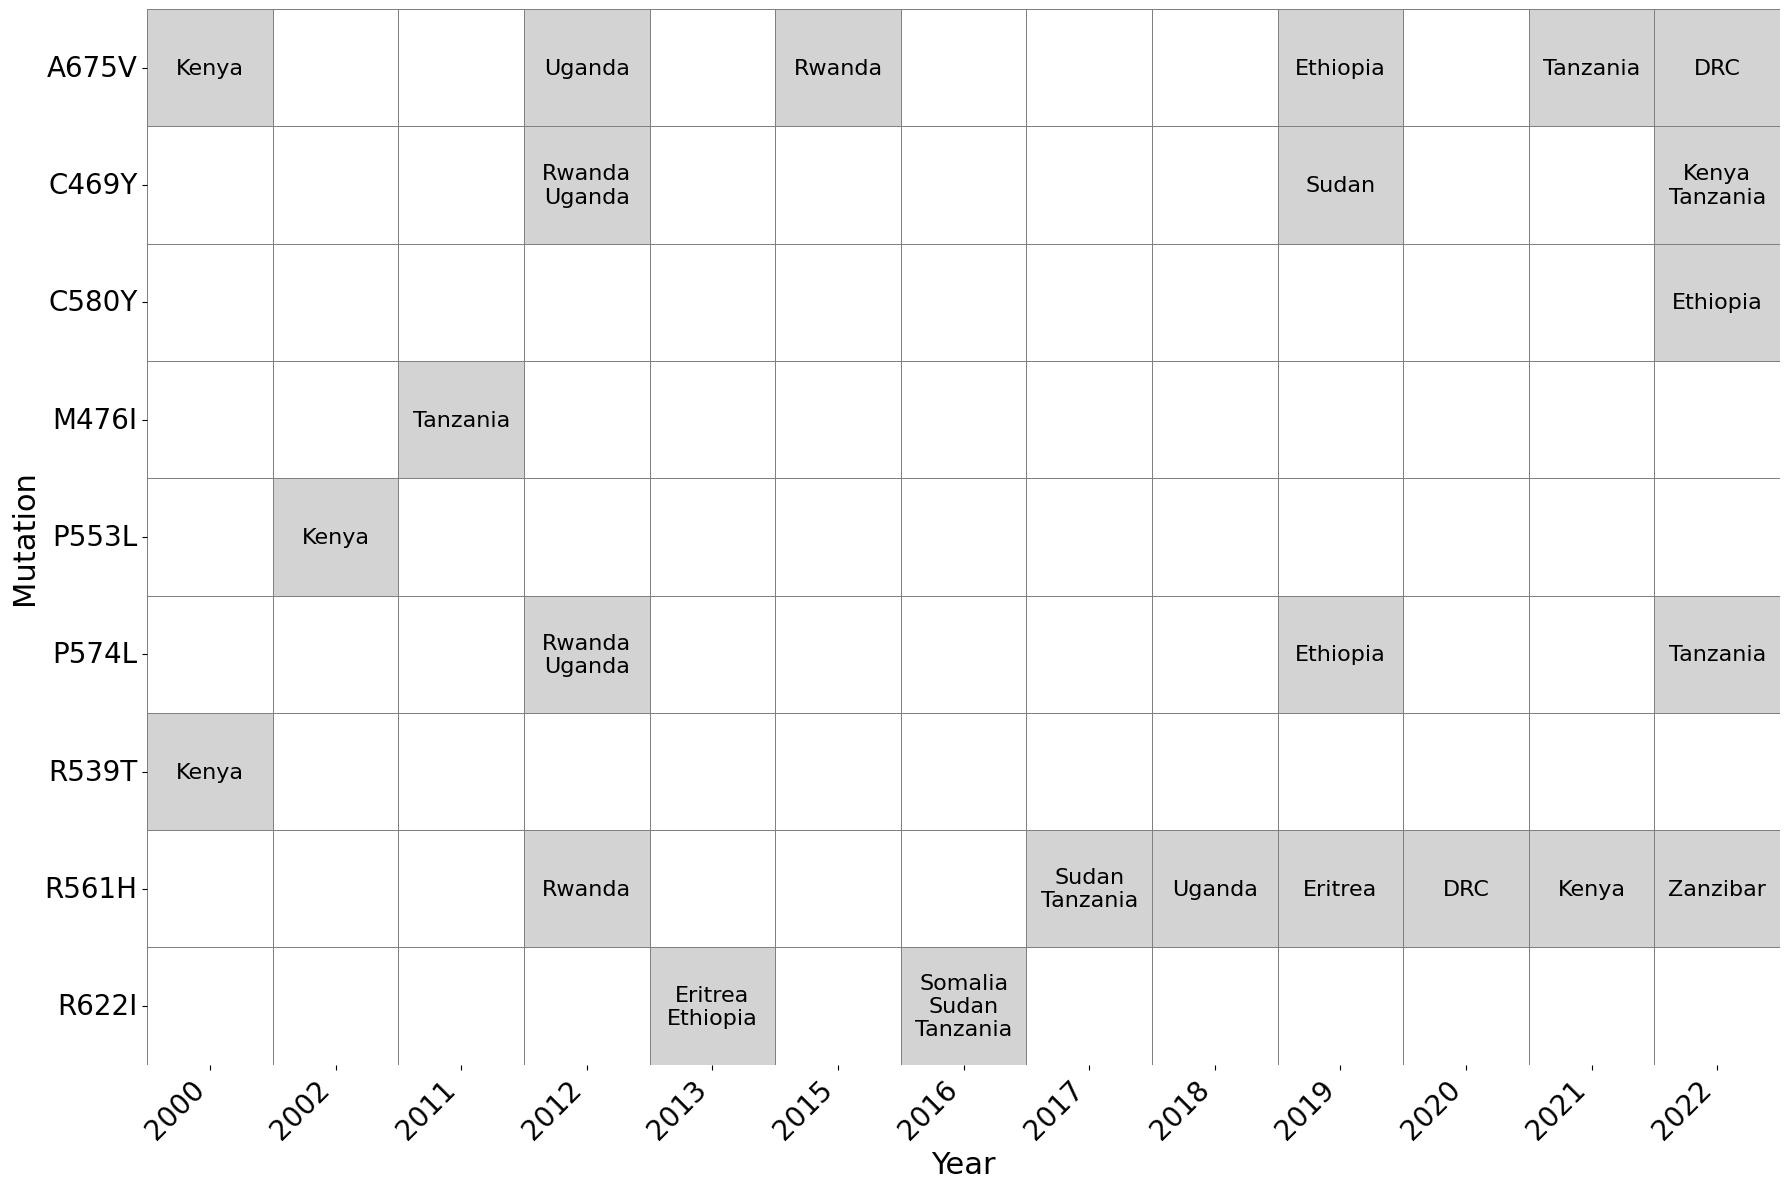

In [46]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# --------------------------------------------------
# STEP 1: Extract earliest year from your data
# --------------------------------------------------

def extract_year(x):
    if pd.notnull(x) and x != "":
        return int(str(x).split("-")[0])
    return np.nan

year_numeric = heatmap_data.map(extract_year)

# --------------------------------------------------
# STEP 2: Convert to long format (Mutation, Year, Country)
# --------------------------------------------------

records = []

for mutation in year_numeric.index:
    for country in year_numeric.columns:
        year = year_numeric.loc[mutation, country]

        if pd.notnull(year):
            records.append({
                "Mutation": mutation,
                "Year": int(year),
                "Country": country
            })

df_long = pd.DataFrame(records)

# --------------------------------------------------
# STEP 3: Pivot → Years as columns
# --------------------------------------------------

heatmap_pivot = df_long.pivot_table(
    index="Mutation",
    columns="Year",
    values="Country",
    aggfunc=lambda x: "\n".join(sorted(set(x)))  # <-- KEY CHANGE: vertical stacking
)

# --------------------------------------------------
# STEP 4: Create annotation + color matrix
# --------------------------------------------------

annot_data = heatmap_pivot.fillna("")

# Presence/absence matrix for coloring
color_matrix = heatmap_pivot.notna().astype(int)

# --------------------------------------------------
# STEP 5: Plot heatmap
# --------------------------------------------------

plt.figure(figsize=(18, 12))

ax = sns.heatmap(
    color_matrix,
    annot=annot_data,
    fmt="",
    cmap=["white", "lightgray"],
    cbar=False,
    linewidths=0.4,
    linecolor="gray",
    annot_kws={
        "fontsize": 16,
        "color": "black",
        "ha": "center",
        "va": "center"
    }
)

# Axis labels
ax.set_xlabel("Year", fontsize=22)
ax.set_ylabel("Mutation", fontsize=22)

# Tick formatting
plt.xticks(rotation=45, ha="right", fontsize=20)
plt.yticks(rotation=0, fontsize=20)

# Improve layout
plt.tight_layout()

# Save figure
plt.savefig("./version7/mutation_by_year_heatmap_scrapped2.png", dpi=400, bbox_inches="tight")

plt.show()

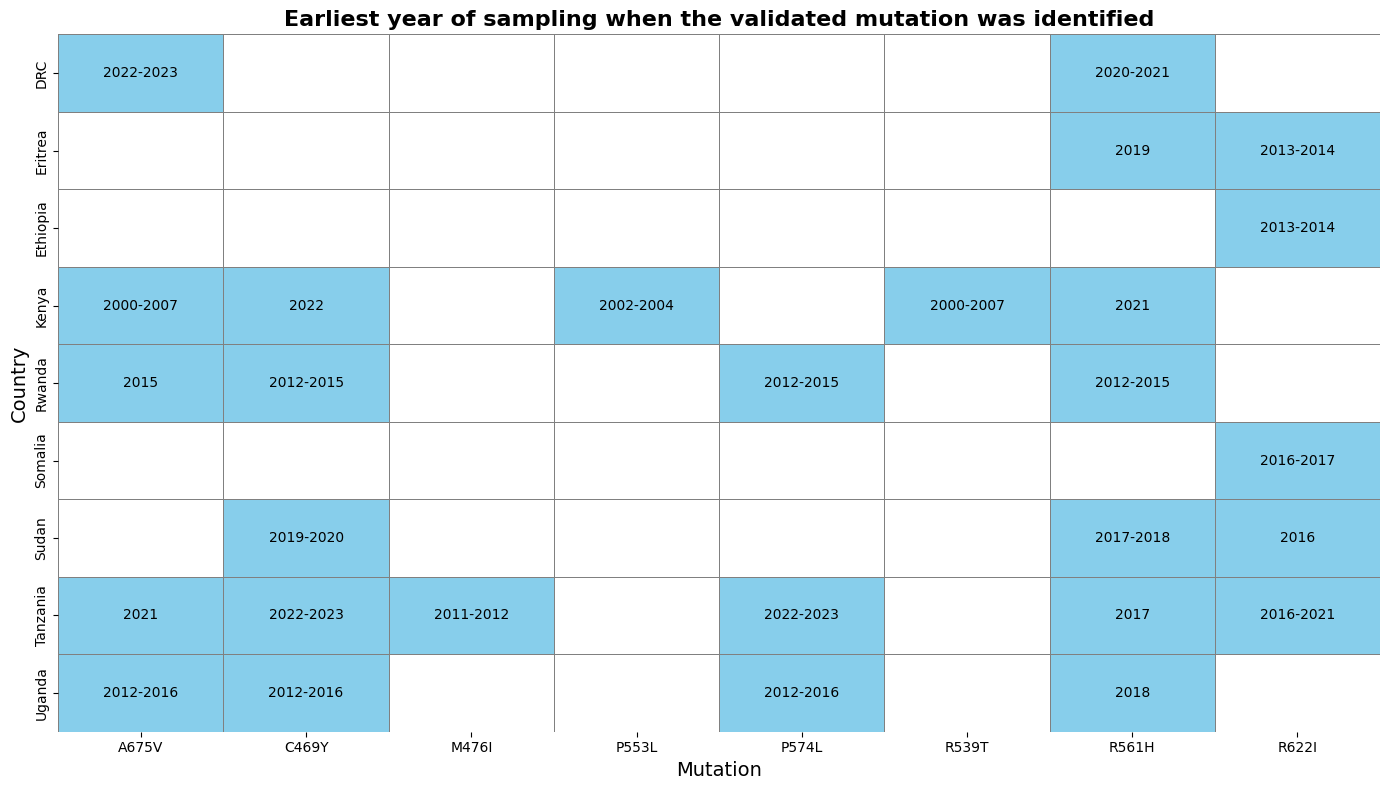

In [18]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Ensure year_sample is string
df2["year_sample"] = df2["year_sample"].astype(str).str.strip()

# Step 2: Extract start and end years
year_pairs = df2["year_sample"].str.extract(r"(?P<start_year>\d{4})\D+(?P<end_year>\d{4})")
single_year = df2["year_sample"].str.extract(r"(?P<year>\d{4})")
year_pairs["start_year"] = year_pairs["start_year"].combine_first(single_year["year"])
year_pairs["end_year"] = year_pairs["end_year"].combine_first(single_year["year"])

# Step 3: Convert to numeric
year_pairs = year_pairs.apply(pd.to_numeric, errors="coerce")

# Step 4: Add back to original DataFrame
df2["start_year"] = year_pairs["start_year"]
df2["end_year"] = year_pairs["end_year"]

# Step 5: Construct a clean year range label
df2["year_range_label"] = df2.apply(
    lambda row: f"{int(row['start_year'])}-{int(row['end_year'])}" if pd.notnull(row["start_year"]) and pd.notnull(row["end_year"]) and row["start_year"] != row["end_year"]
    else f"{int(row['start_year'])}" if pd.notnull(row["start_year"])
    else "Unknown", axis=1
)

# Step 6: Group by country and mutation, pick earliest start year and year label
first_seen = df2.groupby(["country", "Mutation"]).agg({
    "start_year": "min",
    "year_range_label": lambda x: sorted(set(x))[0]
}).reset_index()

# Step 7: Pivot to get country x mutation matrix with year labels
heatmap_data = first_seen.pivot(index="country", columns="Mutation", values="year_range_label")

# Step 8: Create binary matrix: 1 where year is present, 0 where NaN
binary_matrix = heatmap_data.notna().astype(int)

# Step 9: Annotate only where data is present
annot_data = heatmap_data.fillna("")

# Step 10: Plot
plt.figure(figsize=(14, 8))
sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 10, "color": "black", "ha": "center", "va": "center"}
)

plt.title("Earliest year of sampling when the validated mutation was identified", fontsize=16, weight='bold')
plt.xlabel("Mutation", fontsize=14)
plt.ylabel("Country", fontsize=14)
# plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("./version6/first_sampled_mutation_heatmap1.png", dpi=300)
plt.show()


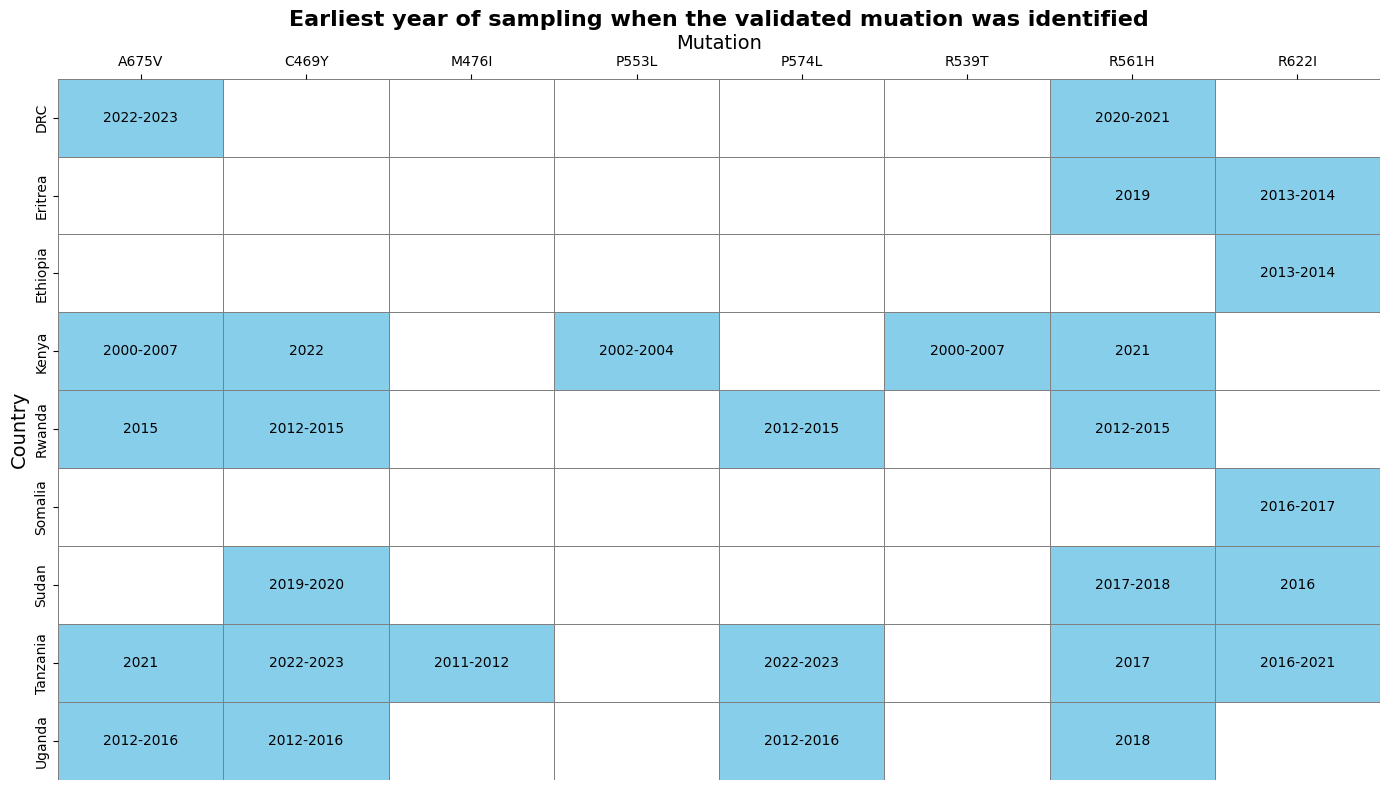

In [21]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 10, "color": "black", "ha": "center", "va": "center"}
)

plt.title("Earliest year of sampling when the validated muation was identified", fontsize=16, weight='bold')
plt.xlabel("Mutation", fontsize=14)
plt.ylabel("Country", fontsize=14)

# ✅ Move x-axis to top
plt.gca().xaxis.set_ticks_position('top')
plt.gca().xaxis.set_label_position('top')

plt.tight_layout()
plt.savefig("./version5/first_sampled_mutation_heatmap2.png", dpi=300)
plt.show()


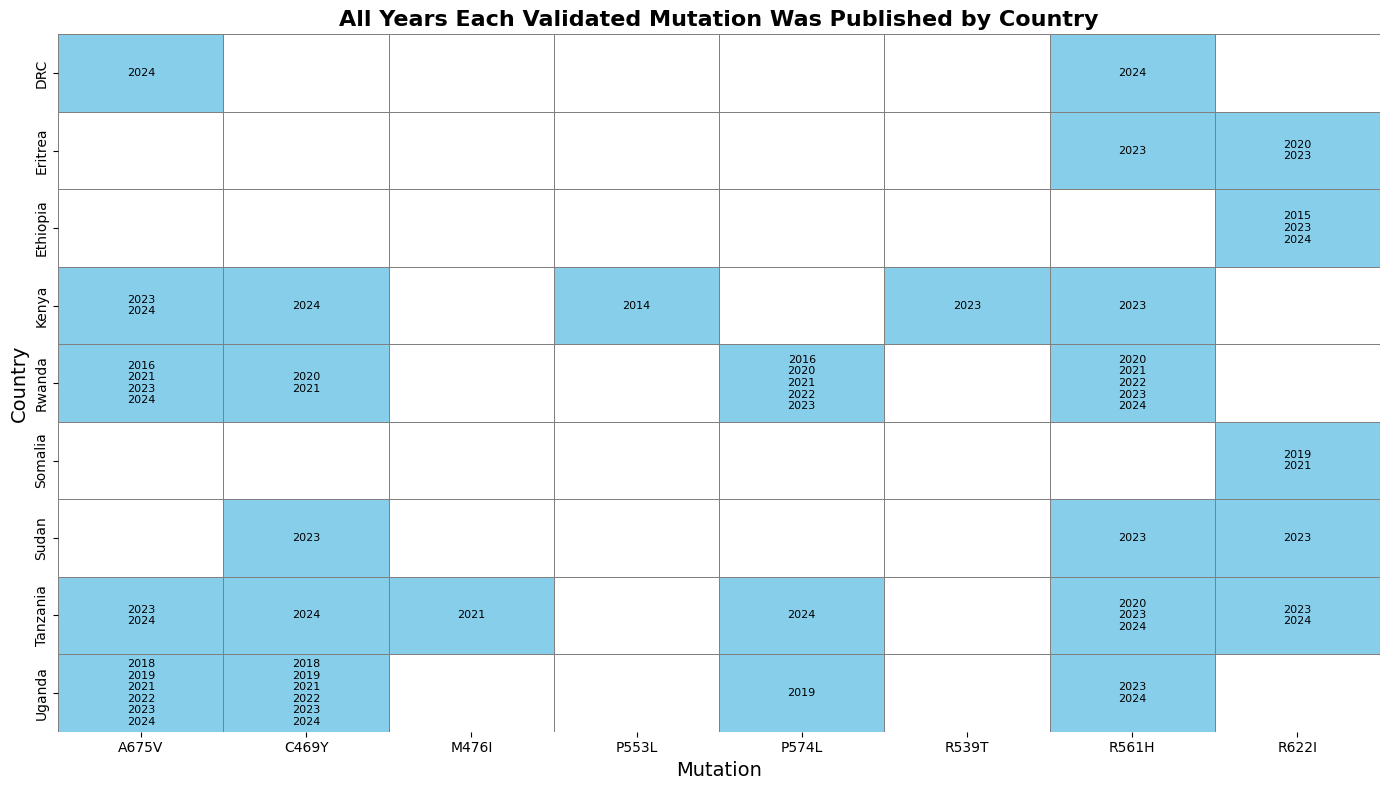

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Ensure year_pub is clean and numeric
df2["year_pub"] = pd.to_numeric(df2["year_pub"], errors="coerce")
df2 = df2.dropna(subset=["year_pub"])
df2["year_pub"] = df2["year_pub"].astype(int)

# Step 2: Clean country and mutation columns
df2["country"] = df2["country"].astype(str).str.strip()
df2["Mutation"] = df2["Mutation"].astype(str).str.strip().str.upper()

# Step 3: Aggregate all years per (country, mutation)
all_years = (
    df2.groupby(["country", "Mutation"])["year_pub"]
    .apply(lambda x: "\n".join(str(y) for y in sorted(set(x))))
    .reset_index()
)

# Step 4: Pivot for heatmap format
heatmap_data = all_years.pivot(index="country", columns="Mutation", values="year_pub")

# Step 5: Create binary mask (1 = present, 0 = NaN) for coloring
binary_mask = heatmap_data.notna().astype(int)

# Step 6: Fill NaNs in label data with blanks
annot_data = heatmap_data.fillna("")

# Step 7: Plot
plt.figure(figsize=(14, 8))
sns.heatmap(
    binary_mask,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 8, "color": "black", "ha": "center", "va": "center"}
)

plt.title("All Years Each Validated Mutation Was Published by Country", fontsize=16, weight='bold')
plt.xlabel("Mutation", fontsize=14)
plt.ylabel("Country", fontsize=14)
plt.tight_layout()
plt.savefig("./version6/all_publication_years_heatmap.png", dpi=300)
plt.savefig("./version6/all_publication_years_heatmap.pdf")
plt.show()

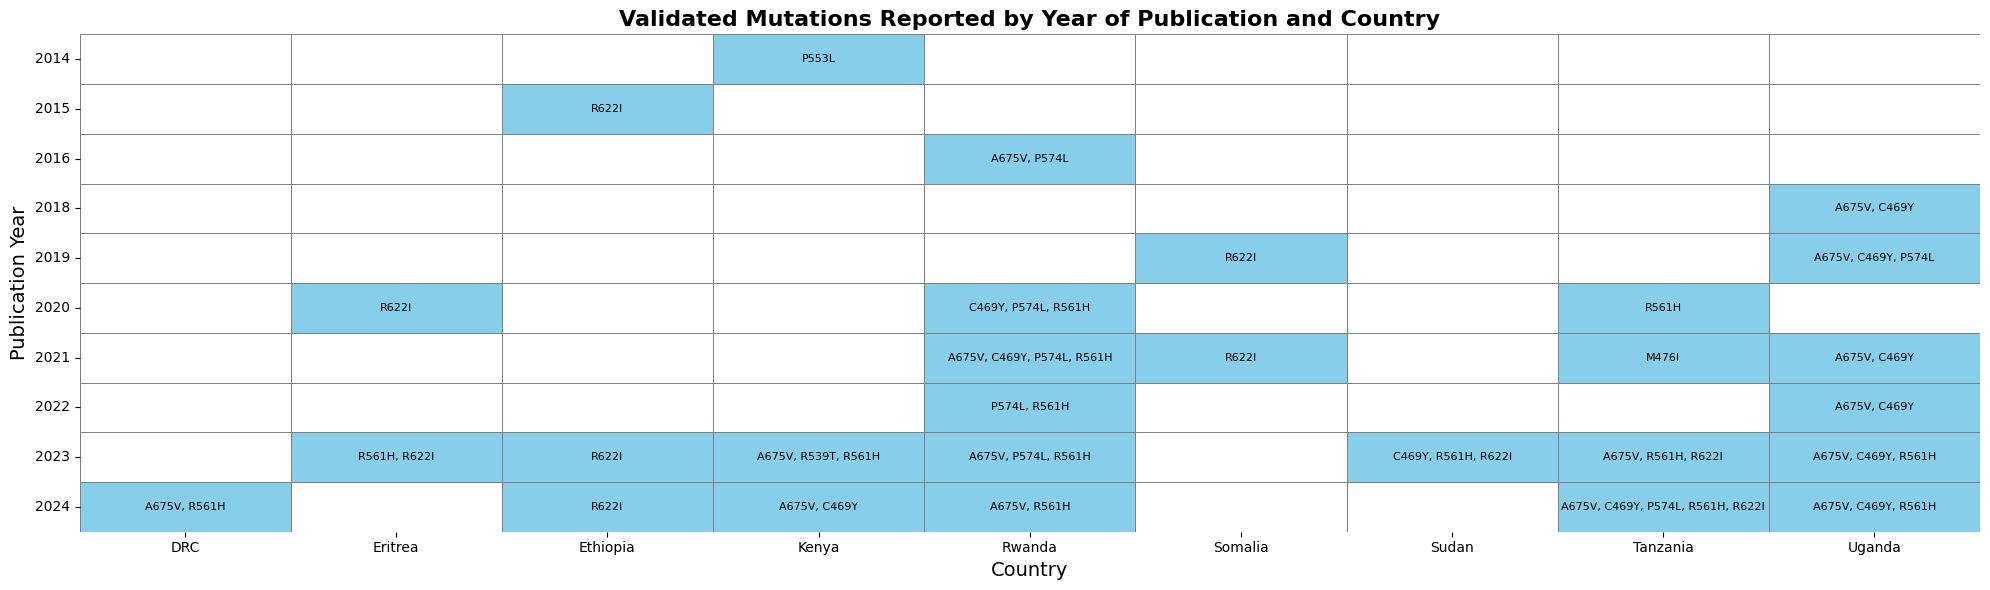

In [37]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Clean and prepare the data
df2["year_pub"] = pd.to_numeric(df2["year_pub"], errors="coerce")
df2 = df2.dropna(subset=["year_pub"])
df2["year_pub"] = df2["year_pub"].astype(int)

df2["country"] = df2["country"].astype(str).str.strip()
df2["Mutation"] = df2["Mutation"].astype(str).str.strip().str.upper()

# Step 2: Group by (year_pub, country), collect unique mutations
grouped = df2.groupby(["year_pub", "country"])["Mutation"].agg(
    lambda x: ", ".join(sorted(set(x)))
).reset_index()

# Step 3: Pivot to year (rows) × country (columns) with mutations in cells
heatmap_data = grouped.pivot(index="year_pub", columns="country", values="Mutation")

# Step 4: Binary presence mask for heatmap background
binary_mask = heatmap_data.notna().astype(int)
annot_data = heatmap_data.fillna("")

# Step 5: Plot
plt.figure(figsize=(16, len(heatmap_data.index) * 0.6))

sns.heatmap(
    binary_mask,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor="gray",
    annot_kws={"fontsize": 8, "color": "black", "ha": "center", "va": "center"}
)

plt.title("Validated Mutations Reported by Year of Publication and Country", fontsize=16, weight="bold")
plt.xlabel("Country", fontsize=14)
plt.ylabel("Publication Year", fontsize=14)
#plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save outputs
plt.savefig("./version6/publication_by_year_and_country_heatmap.png", dpi=300)
plt.savefig("./version6/publication_by_year_and_country_heatmap.pdf")
plt.show()

# Optional: Save to Excel and Word
heatmap_data.to_excel("./version6/publication_by_year_and_country.xlsx")

from docx import Document
doc = Document()
doc.add_heading("Validated Mutations by Year of Publication and Country", 0)

table = doc.add_table(rows=1, cols=len(heatmap_data.columns) + 1)
table.style = "Table Grid"

# Header
hdr_cells = table.rows[0].cells
hdr_cells[0].text = "Year"
for i, country in enumerate(heatmap_data.columns):
    hdr_cells[i + 1].text = country

# Rows
for year, row in heatmap_data.iterrows():
    row_cells = table.add_row().cells
    row_cells[0].text = str(year)
    for i, val in enumerate(row):
        row_cells[i + 1].text = str(val) if pd.notna(val) else ""

doc.save("./version6/publication_by_year_and_country.docx")


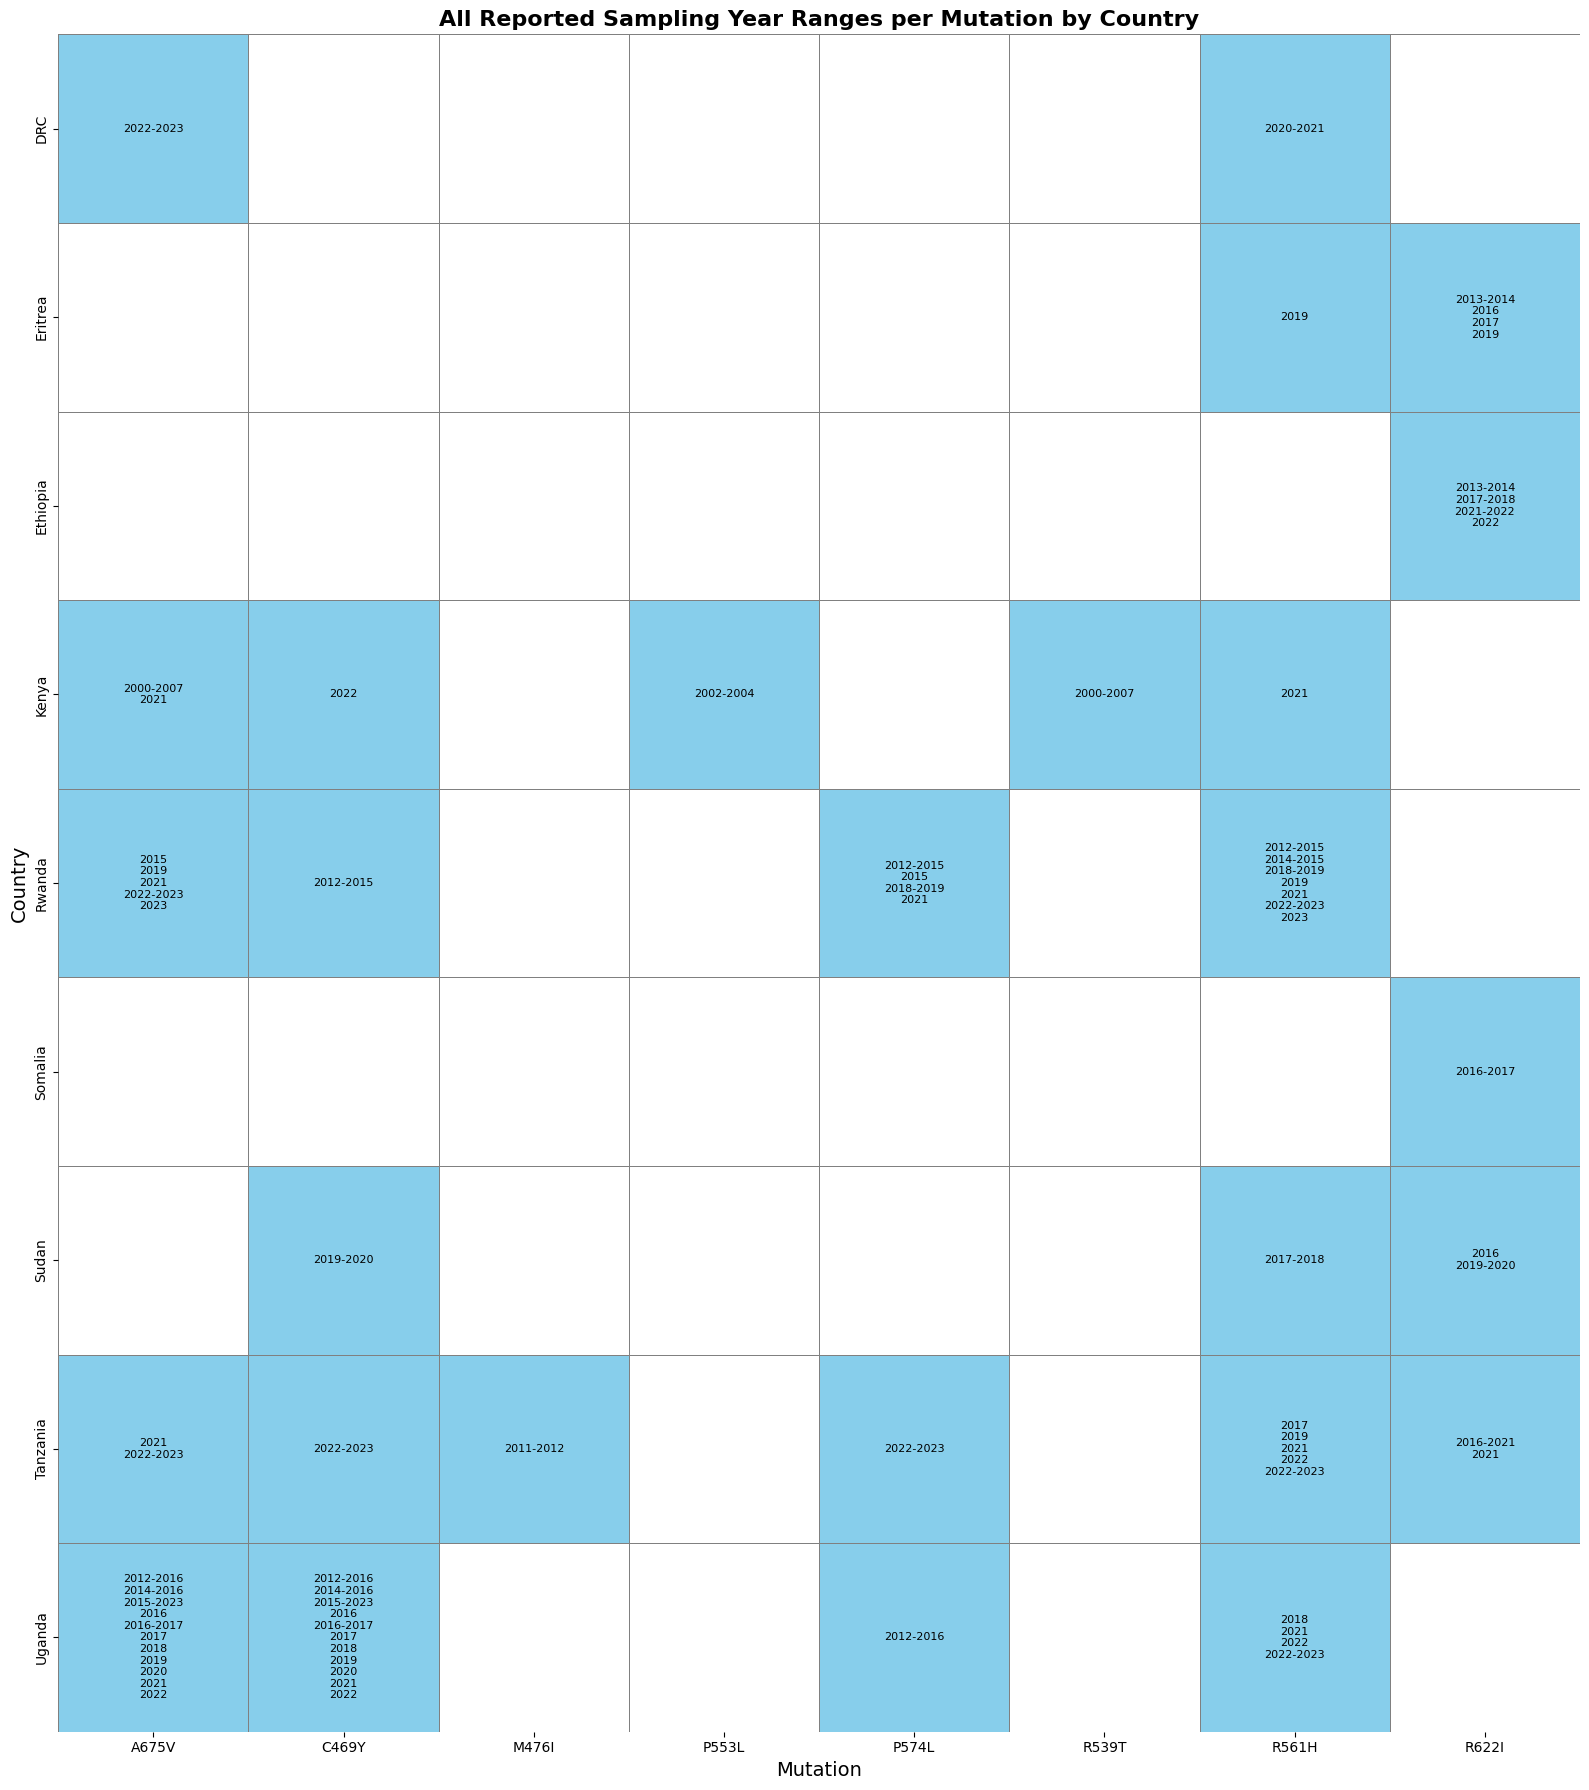

In [21]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# -----------------------------
# Step 1: Extract year ranges
# -----------------------------
df2["year_sample"] = df2["year_sample"].astype(str).str.strip()

# Extract start and end years
year_pairs = df2["year_sample"].str.extract(r"(?P<start_year>\d{4})\D+(?P<end_year>\d{4})")
single_year = df2["year_sample"].str.extract(r"(?P<year>\d{4})")
year_pairs["start_year"] = year_pairs["start_year"].combine_first(single_year["year"])
year_pairs["end_year"] = year_pairs["end_year"].combine_first(single_year["year"])

# Convert to numeric
year_pairs = year_pairs.apply(pd.to_numeric, errors="coerce")

# Add back to original DataFrame
df2["start_year"] = year_pairs["start_year"]
df2["end_year"] = year_pairs["end_year"]

# Clean year label: 2002-2004 or 2002
df2["year_range_label"] = df2.apply(
    lambda row: f"{int(row['start_year'])}-{int(row['end_year'])}" if pd.notnull(row["start_year"]) and pd.notnull(row["end_year"]) and row["start_year"] != row["end_year"]
    else f"{int(row['start_year'])}" if pd.notnull(row["start_year"])
    else None,
    axis=1
)

# Drop missing year entries
df2 = df2.dropna(subset=["year_range_label"])

# -----------------------------
# Step 2: Group and aggregate
# -----------------------------
# Collect all distinct year ranges per (country, mutation)
heatmap_df = df2.groupby(["country", "Mutation"])["year_range_label"].agg(lambda x: "\n".join(sorted(set(x)))).reset_index()

# Pivot to country x mutation matrix
heatmap_data = heatmap_df.pivot(index="country", columns="Mutation", values="year_range_label")

# Binary matrix: 1 where data is present
binary_matrix = heatmap_data.notna().astype(int)
annot_data = heatmap_data.fillna("")

# -----------------------------
# Step 3: Plotting
# -----------------------------
# Automatically scale row height based on number of countries
row_height = 2.0
n_rows = heatmap_data.shape[0]
fig_height = row_height * n_rows

plt.figure(figsize=(16, fig_height))

sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 8, "color": "black", "ha": "center", "va": "center"}
)

# Format plot
plt.title("All Reported Sampling Year Ranges per Mutation by Country", fontsize=16, weight='bold')
plt.xlabel("Mutation", fontsize=14)
plt.ylabel("Country", fontsize=14)

# Put x-axis labels (mutations) on top
#plt.gca().xaxis.tick_top()
#plt.gca().xaxis.set_label_position('top')

plt.tight_layout()
plt.savefig("./version6/all_sample_years_heatmap.png", dpi=300)
plt.savefig("./version6/all_sample_years_heatmap.pdf")
plt.show()


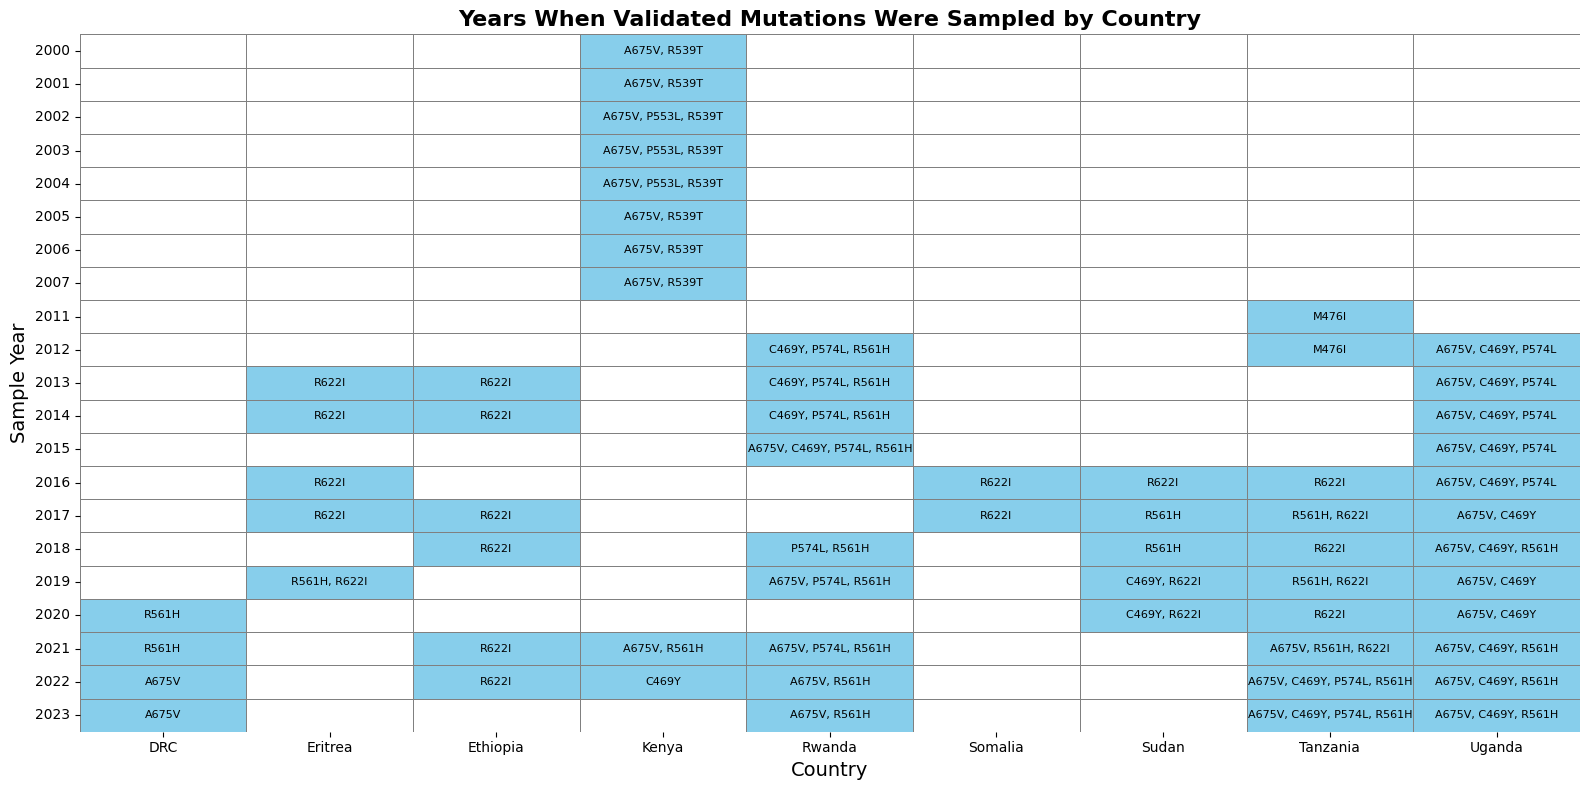

In [24]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Clean and extract year(s)
df2["year_sample"] = df2["year_sample"].astype(str).str.strip()

# Extract start and end year
year_pairs = df2["year_sample"].str.extract(r"(?P<start_year>\d{4})\D+(?P<end_year>\d{4})")
single_year = df2["year_sample"].str.extract(r"(?P<year>\d{4})")
year_pairs["start_year"] = year_pairs["start_year"].combine_first(single_year["year"])
year_pairs["end_year"] = year_pairs["end_year"].combine_first(single_year["year"])
year_pairs = year_pairs.apply(pd.to_numeric, errors="coerce")

# Add year ranges back to df2
df2["start_year"] = year_pairs["start_year"]
df2["end_year"] = year_pairs["end_year"]

# Step 2: Expand year ranges (important!)
df2 = df2.dropna(subset=["start_year"])
df2["end_year"] = df2["end_year"].fillna(df2["start_year"])

df_expanded = df2.loc[df2.index.repeat(df2["end_year"] - df2["start_year"] + 1)].copy()
df_expanded["year"] = df_expanded.groupby(level=0).cumcount() + df_expanded["start_year"]

# Step 3: Group by (year, country) and join mutations with commas
grouped = df_expanded.groupby(["year", "country"])["Mutation"].agg(
    lambda x: ", ".join(sorted(set(x)))
).reset_index()

# Step 4: Pivot
heatmap_data = grouped.pivot(index="year", columns="country", values="Mutation")

# Binary presence matrix
binary_matrix = heatmap_data.notna().astype(int)
annot_data = heatmap_data.fillna("")

# Step 5: Plot
plt.figure(figsize=(16, 8))
sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 8, "color": "black", "ha": "center", "va": "center"}
)

plt.title("Years When Validated Mutations Were Sampled by Country", fontsize=16, weight='bold')
plt.xlabel("Country", fontsize=14)
plt.ylabel("Sample Year", fontsize=14)
plt.yticks(rotation=0)
#plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig("./version6/all_sample_years_heatmap_blue.png", dpi=300)
plt.savefig("./version6/all_sample_years_heatmap_blue.pdf")

plt.show()


In [25]:
# Save the final table with mutations per year_range and country to Excel
heatmap_data.to_excel("./version6/all_sample_years_heatmap_table.xlsx", index=True)

In [26]:
from docx import Document
from docx.shared import Inches

# Create a new Word document
doc = Document()
doc.add_heading("Reported Validated Mutations by Country and Year Range", 0)

# Add table
table = doc.add_table(rows=1, cols=len(heatmap_data.columns) + 1)
table.style = 'Table Grid'

# Header row
hdr_cells = table.rows[0].cells
hdr_cells[0].text = "Year Range"
for i, col in enumerate(heatmap_data.columns):
    hdr_cells[i + 1].text = col

# Add data rows
for idx, row in heatmap_data.iterrows():
    cells = table.add_row().cells
    cells[0].text = str(idx)
    for j, value in enumerate(row):
        cells[j + 1].text = str(value) if pd.notna(value) else ""

# Save Word document
doc.save("./version6/all_sample_years_heatmap_table.docx")

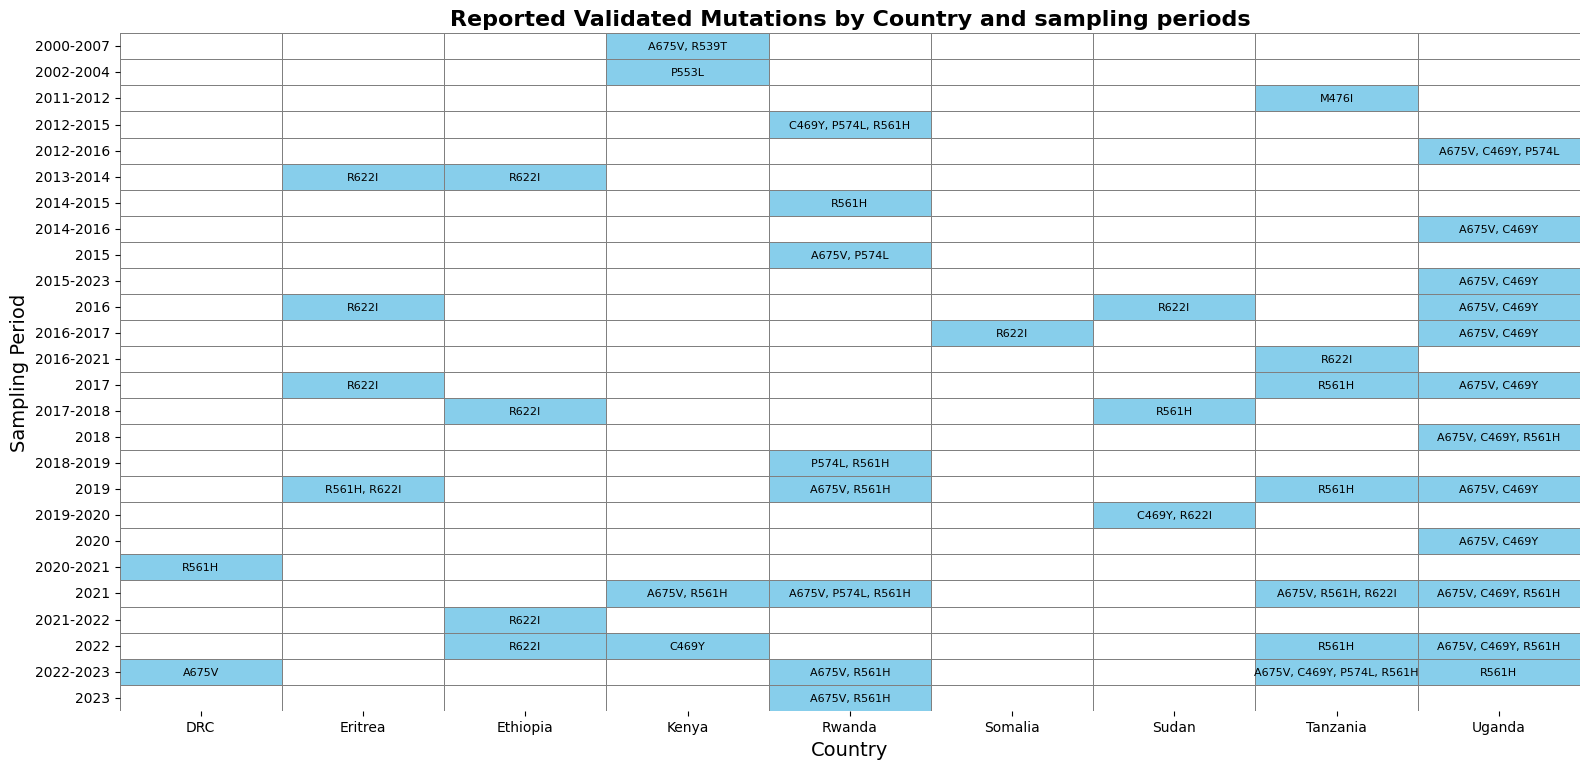

In [28]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Step 1: Ensure 'year_sample' is string
df2["year_sample"] = df2["year_sample"].astype(str).str.strip()

# Step 2: Extract start and end years (if range) or single year
year_pairs = df2["year_sample"].str.extract(r"(?P<start_year>\d{4})\D+(?P<end_year>\d{4})")
single_year = df2["year_sample"].str.extract(r"(?P<year>\d{4})")

year_pairs["start_year"] = year_pairs["start_year"].combine_first(single_year["year"])
year_pairs["end_year"] = year_pairs["end_year"].combine_first(single_year["year"])

year_pairs = year_pairs.apply(pd.to_numeric, errors="coerce")
df2["start_year"] = year_pairs["start_year"]
df2["end_year"] = year_pairs["end_year"]

# Optional: Create a clean year_range column for labeling
df2["year_range"] = df2.apply(
    lambda row: f"{int(row['start_year'])}-{int(row['end_year'])}" if pd.notnull(row["start_year"]) and pd.notnull(row["end_year"]) and row["start_year"] != row["end_year"]
    else f"{int(row['start_year'])}" if pd.notnull(row["start_year"])
    else None,
    axis=1
)

# Step 3: Remove missing year_range
df2 = df2.dropna(subset=["year_range"])

# Step 4: Group by (year_range, country) and join mutations with commas
grouped = df2.groupby(["year_range", "country"])["Mutation"].agg(lambda x: ", ".join(sorted(set(x)))).reset_index()

# Step 5: Pivot to year_range x country
heatmap_data = grouped.pivot(index="year_range", columns="country", values="Mutation")

# Step 6: Binary presence matrix
binary_matrix = heatmap_data.notna().astype(int)
annot_data = heatmap_data.fillna("")

# Step 7: Plot
plt.figure(figsize=(16, len(heatmap_data.index) * 0.3))
sns.heatmap(
    binary_matrix,
    annot=annot_data,
    fmt="",
    cmap=sns.color_palette(["white", "skyblue"]),
    cbar=False,
    linewidths=0.5,
    linecolor='gray',
    annot_kws={"fontsize": 8, "color": "black", "ha": "center", "va": "center"}
)

plt.title("Reported Validated Mutations by Country and sampling periods", fontsize=16, weight='bold')
plt.xlabel("Country", fontsize=14)
plt.ylabel("Sampling Period", fontsize=14)
#plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

# Save or show the figure
plt.savefig("./version6/mutation_by_year_range_heatmap_blue.png", dpi=300)
plt.savefig("./version6/mutation_by_year_range_heatmap_blue.pdf")
plt.show()

In [29]:
# Save the final table with mutations per year_range and country to Excel
heatmap_data.to_excel("./version6/mutation_by_year_range_table.xlsx", index=True)

In [197]:
pip install python-docx

Note: you may need to restart the kernel to use updated packages.


In [30]:
from docx import Document
from docx.shared import Inches

# Create a new Word document
doc = Document()
doc.add_heading("Reported Validated Mutations by Country and Year Range", 0)

# Add table
table = doc.add_table(rows=1, cols=len(heatmap_data.columns) + 1)
table.style = 'Table Grid'

# Header row
hdr_cells = table.rows[0].cells
hdr_cells[0].text = "Year Range"
for i, col in enumerate(heatmap_data.columns):
    hdr_cells[i + 1].text = col

# Add data rows
for idx, row in heatmap_data.iterrows():
    cells = table.add_row().cells
    cells[0].text = str(idx)
    for j, value in enumerate(row):
        cells[j + 1].text = str(value) if pd.notna(value) else ""

# Save Word document
doc.save("./version6/mutation_by_year_range_table.docx")

In [31]:
import pandas as pd

# Step 1: Ensure the necessary columns are clean
df["pmid"] = df["pmid"].astype(str).str.strip()
df["k13_validated_mutations"] = df["k13_validated_mutations"].astype(str).str.strip()
df["percentage_frequency"] = pd.to_numeric(df["percentage_frequency"], errors="coerce")
df["country"] = df["country"].astype(str).str.strip()
df["town"]=df["town"].astype(str).str.strip()
df["year_sample"] = df["year_sample"].astype(str).str.strip()
df["genotyping_assay"] = df["genotyping_assay"].astype(str).str.strip()
df["samples_genotyped"] = df["samples_genotyped"].astype(str).str.strip()

# Step 2: Remove rows with missing or "-" mutations
df = df[df["k13_validated_mutations"].notna() & (df["k13_validated_mutations"] != "-")]

# Step 3: Only keep rows where frequency is greater than 0
df = df[df["percentage_frequency"] > 0]

# Step 4: Explode mutations into individual rows
df = df.assign(Mutation=df["k13_validated_mutations"].str.split(r",\s*")).explode("Mutation")
df["Mutation"] = df["Mutation"].str.strip().str.upper()

# Step 5: Format frequency as a string with percent sign
df["percentage_label"] = df["percentage_frequency"].astype(str) + "%"

# Step 6: Pivot the table so each mutation is a column
pivot = df.pivot_table(
    index=["pmid", "year_sample", "country", "town", "genotyping_assay", "samples_genotyped"],
    columns="Mutation",
    values="percentage_label",
    aggfunc="first"  # Only one value per mutation per PMID
).reset_index()

# Step 7: Optional - reorder columns
meta_cols = ["pmid", "year_sample", "country", "town", "genotyping_assay", "samples_genotyped"]
mutation_cols = sorted([col for col in pivot.columns if col not in meta_cols])
final_table = pivot[meta_cols + mutation_cols]

# Step 8: View the result
final_table

# Optional: Save to Excel
final_table.to_excel("./version6/validated_mutations_summary_by_pmid1.xlsx", index=False)


### Include raw counts in brackets

In [32]:
import pandas as pd

# Step 1: Ensure the necessary columns are clean
df["pmid"] = df["pmid"].astype(str).str.strip()
df["k13_validated_mutations"] = df["k13_validated_mutations"].astype(str).str.strip()
df["percentage_frequency"] = pd.to_numeric(df["percentage_frequency"], errors="coerce")
df["raw_count"] = pd.to_numeric(df["raw_count"], errors="coerce")
df["country"] = df["country"].astype(str).str.strip()
df["town"] = df["town"].astype(str).str.strip()
df["year_sample"] = df["year_sample"].astype(str).str.strip()
df["genotyping_assay"] = df["genotyping_assay"].astype(str).str.strip()
df["samples_genotyped"] = df["samples_genotyped"].astype(str).str.strip()

# Step 2: Remove rows with missing or "-" mutations
df = df[df["k13_validated_mutations"].notna() & (df["k13_validated_mutations"] != "-")]

# Step 3: Only keep rows where frequency is greater than 0
df = df[df["percentage_frequency"] > 0]

# Step 4: Explode mutations into individual rows
df = df.assign(Mutation=df["k13_validated_mutations"].str.split(r",\s*")).explode("Mutation")
df["Mutation"] = df["Mutation"].str.strip().str.upper()

# Step 5: Format frequency as "7.7 [5]" (no percent sign)
df["percentage_label"] = df.apply(
    lambda row: f"{row['percentage_frequency']} [{int(row['raw_count'])}]" if pd.notnull(row['raw_count'])
    else f"{row['percentage_frequency']}", axis=1
)

# Step 6: Pivot the table so each mutation is a column
pivot = df.pivot_table(
    index=["pmid", "year_sample", "country", "town", "genotyping_assay", "samples_genotyped"],
    columns="Mutation",
    values="percentage_label",
    aggfunc="first"  # Only one value per mutation per PMID
).reset_index()

# Step 7: Optional - reorder columns
meta_cols = ["pmid", "year_sample", "country", "town", "genotyping_assay", "samples_genotyped"]
mutation_cols = sorted([col for col in pivot.columns if col not in meta_cols])
final_table = pivot[meta_cols + mutation_cols]

# Step 8: View the result
final_table

# Optional: Save to Excel
final_table.to_excel("./version6/validated_mutations_summary_by_pmid_with_counts_no_percent.xlsx", index=False)


In [67]:
df2.head()

,pmid,year_pub,year_sample,country,region/province,town,participants_age,participants_age_unit,sample_size,first_line_act,...,mutation_frequency_(%),where_sequenced,other_k13_mutations,data_extraction_comments,journal_access,raw_count,percentage_frequency,latitude,longitude,Mutation
0,34551228,2021.0,2015,Uganda,Northern-Uganda,Gulu,≥0.5,years,77,AL,...,0,missing,-,raw counts,open,0.0,0.0,2.85604,32.43001,C469Y
1,34551228,2021.0,2015,Uganda,Northern-Uganda,Gulu,≥0.5,years,77,AL,...,0,missing,-,raw counts,open,0.0,0.0,2.85604,32.43001,A675V
2,34551228,2021.0,2016,Uganda,Northern-Uganda,Gulu,≥0.5,years,94,AL,...,0,missing,-,raw counts,open,0.0,0.0,2.85604,32.43001,C469Y
3,34551228,2021.0,2016,Uganda,Northern-Uganda,Gulu,≥0.5,years,94,AL,...,3 (3.4),missing,-,raw counts,open,3.0,3.4,2.85604,32.43001,A675V
4,34551228,2021.0,2017,Uganda,Northern-Uganda,Gulu,≥0.5,years,101,AL,...,0,missing,-,raw counts,open,0.0,0.0,2.85604,32.43001,C469Y


#### K13_mutation_distribution

In [35]:
# Clean and ensure correct types
df["k13_validated_mutations"] = df["k13_validated_mutations"].fillna("").astype(str)
df["country"] = df["country"].fillna("").astype(str)
df["pmid"] = df["pmid"].astype(str)

# Filter out empty mutation entries
filtered_df = df[
    df["k13_validated_mutations"].str.strip().ne("") &
    df["k13_validated_mutations"].str.strip().ne("-")]

# Group by mutation and summarize
summary_df = filtered_df.groupby("k13_validated_mutations").agg({
    "country": lambda x: ", ".join(sorted(set(i.strip() for i in x if i and i.strip()))),
    "pmid": lambda x: sorted(set(i.strip() for i in x if i and i.strip() and i != "nan"))
}).reset_index()

# Add PMID count and list as separate columns
summary_df["Num_PMIDs"] = summary_df["pmid"].apply(len)
summary_df["PMID_List"] = summary_df["pmid"].apply(lambda x: ", ".join(x))

# Rename columns for clarity
summary_df = summary_df[["k13_validated_mutations", "country", "Num_PMIDs", "PMID_List"]]
summary_df.columns = ["Mutation", "Countries", "Num_PMIDs", "PMIDs"]

# Preview
summary_df

#summary_df.to_excel("./version5/mutation_distribution_per_country.xlsx", index=False)

,Mutation,Countries,Num_PMIDs,PMIDs
0,A675V,"DRC, Kenya, Rwanda, Tanzania, Uganda",19,"10.2139/SSRN.4617870, 27573632, 29553316, 3055..."
1,C469Y,"Kenya, Rwanda, Sudan, Tanzania, Uganda",16,"10.1101/2021.01.27.428390, 29553316, 30559133,..."
2,M476I,Tanzania,1,10.1101/2021.01.27.428390
3,P553L,Kenya,1,25180240
4,P574L,"Rwanda, Tanzania, Uganda",7,"10.1101/2021.01.27.428390, 27573632, 31358588,..."
5,R539T,Kenya,1,10.2139/SSRN.4617870
6,R561H,"DRC, Eritrea, Kenya, Rwanda, Sudan, Tanzania, ...",18,"10.1101/2021.01.27.428390, 32103124, 32747827,..."
7,R622I,"Eritrea, Ethiopia, Somalia, Sudan, Tanzania",13,"10.1101/2021.01.27.428390, 10.2139/ssrn.493804..."


#### Literature based proportion of the different k13_validated_mutations

In [40]:
df

,pmid,year_pub,year_sample,country,region/province,town,participants_age,participants_age_unit,sample_size,first_line_act,...,type_of_mutation,mutation_frequency(%),where_sequenced,other_k13_mutations,data_extraction_comments,journal_access,latitude,longitude,raw_count,percentage_frequency
0,34551228,2021,2015-2019,UGANDA,NORTHERN UGANDA,GULU,≥0.5,YEARS,274,AL,...,NON-SYNONYMOUS,27,MISSING,-,RAW_COUNTS,OPEN,1.3730,32.290,27.0,11.25
1,34551228,2021,2015-2029,UGANDA,NORTHERN UGANDA,GULU,≥0.5,YEARS,274,AL,...,NON-SYNONYMOUS,5,MISSING,-,RAW_COUNTS,OPEN,1.3730,32.290,5.0,2.08
2,35703955,2022,missing,DRC,CENTRAL DRC,KINSHASHA,03-Jun,YEARS,118,ASAQ,...,MISSING,0,MISSING,"A578S, Q613E, S522C",RAW_COUNTS,OPEN,4.0380,21.759,0.0,0.00
3,36036611,2022,2016-2017,KENYA,WESTERN KENYA,SIAYA,<5,YEARS,340,AL,...,MISSING,0,MISSING,-,RAW_COUNTS,OPEN,0.0234,37.906,0.0,0.00
4,39136468,2024,2015-2023,UGANDA,EASTERN UGANDA,"TORORO, BUSIA, MBALE",>0.5,YEARS,1112,AL,...,NON-SYNONYMOUS,4,MISSING,A578S,RAW_COUNTS,OPEN,1.3730,32.290,4.0,0.36
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
658,37611122,2023,2022,UGANDA,RUKIGA,RUKIGA,missing,-,100,AL,...,NON-SYNONYMOUS,5.1,MISSING,-,PERCENTAGE,OPEN,1.3730,32.290,3.0,5.10
659,37611122,2023,2022,UGANDA,RUKIGA,RUKIGA,missing,-,100,AL,...,NON-SYNONYMOUS,22.6,MISSING,-,PERCENTAGE,OPEN,1.3730,32.290,12.0,22.60
660,37611122,2023,2022,UGANDA,TORORO,TORORO,missing,-,100,AL,...,NON-SYNONYMOUS,9.8,MISSING,-,PERCENTAGE,OPEN,1.3730,32.290,5.0,9.80
661,37611122,2023,2022,UGANDA,TORORO,TORORO,missing,-,100,AL,...,NON-SYNONYMOUS,15.8,MISSING,-,PERCENTAGE,OPEN,1.3730,32.290,9.0,15.80


In [46]:
import pandas as pd

df = pd.read_excel("cleaned_k13_2_latest.xlsx")

# Clean up columns
df.columns = df.columns.str.strip().str.lower()
df["k13_validated_mutations"] = df["k13_validated_mutations"].fillna("").astype(str).str.strip()
df["pmid"] = df["pmid"].fillna("").astype(str).str.strip()

# Remove empty mutation or pmid entries
df = df[(df["k13_validated_mutations"] != "") & (df["pmid"] != "") & (df["pmid"] != "nan")]

# df = df[df["validated_k13_mutations"] != "-"]

# Count unique PMIDs per mutation
mutation_pmid_count = df.groupby("k13_validated_mutations")["pmid"].nunique().reset_index()
mutation_pmid_count.columns = ["Mutation", "Num_PMIDs"]

# Calculate proportion
total_pmids = df["pmid"].nunique()
mutation_pmid_count["PMID_Proportion"] = (mutation_pmid_count["Num_PMIDs"] / total_pmids).round(3)

# Preview
print(mutation_pmid_count.sort_values("Num_PMIDs", ascending=False).head())

  Mutation  Num_PMIDs  PMID_Proportion
0        -         60            0.652
1    A675V         20            0.217
7    R561H         16            0.174
2    C469Y         15            0.163
8    R622I         11            0.120


In [47]:
mutation_pmid_count

,Mutation,Num_PMIDs,PMID_Proportion
0,-,60,0.652
1,A675V,20,0.217
2,C469Y,15,0.163
3,I543T,1,0.011
4,M476I,1,0.011
5,P574L,6,0.065
6,R539T,2,0.022
7,R561H,16,0.174
8,R622I,11,0.120
9,Y493H,1,0.011


#### Excluding the - rows

In [49]:
import pandas as pd

df = pd.read_excel("cleaned_k13_2_latest.xlsx")

# Clean columns
df.columns = df.columns.str.strip().str.lower()
df["k13_validated_mutations"] = df["k13_validated_mutations"].astype(str).str.strip()
df["pmid"] = df["pmid"].astype(str).str.strip()

# Total unique PMIDs across all rows (including '-')
total_pmids = df["pmid"].nunique()

# Count unique PMIDs per mutation (including '-' for now)
mutation_counts = df.groupby("k13_validated_mutations")["pmid"].nunique().reset_index()
mutation_counts.columns = ["Mutation", "Num_PMIDs"]

# Calculate proportion using the full total
mutation_counts["PMID_Proportion"] = (mutation_counts["Num_PMIDs"] / total_pmids).round(3)

# Now remove rows where Mutation is '-'
mutation_counts = mutation_counts[mutation_counts["Mutation"] != "-"]

# Preview
print(mutation_counts.sort_values("Num_PMIDs", ascending=False).head())


  Mutation  Num_PMIDs  PMID_Proportion
1    A675V         20            0.217
7    R561H         16            0.174
2    C469Y         15            0.163
8    R622I         11            0.120
5    P574L          6            0.065


In [51]:
mutation_counts

,Mutation,Num_PMIDs,PMID_Proportion
1,A675V,20,0.217
2,C469Y,15,0.163
3,I543T,1,0.011
4,M476I,1,0.011
5,P574L,6,0.065
6,R539T,2,0.022
7,R561H,16,0.174
8,R622I,11,0.120
9,Y493H,1,0.011


In [52]:
mutation_counts.to_excel("literature_based_frequency.xlsx", index=False)

### Proportion of non-validated mutations

In [4]:
import pandas as pd

# Load the Excel file
df = pd.read_excel("K13_non_validated_v6.xlsx")

# Filter and count
mutation_summary = (
    df[df['other_k13_mutations'] != '-']
    .groupby('other_k13_mutations')
    .size()
    .reset_index(name='count')
)

# Calculate proportions
mutation_summary['proportion'] = mutation_summary['count'] / mutation_summary['count'].sum()

# Sort
mutation_summary = mutation_summary.sort_values(by='count', ascending=False)

# Display
print(mutation_summary)

# Number of unique mutations
print("Total unique non-validated K13 mutations:", mutation_summary.shape[0])


    other_k13_mutations  count  proportion
46                A578S    103    0.087585
167               K189T     82    0.069728
178               L258M     27    0.022959
64                C469F     26    0.022109
234               P441L     23    0.019558
..                  ...    ...         ...
347               Y500Y      1    0.000850
10                K108E      1    0.000850
0                 A626S      1    0.000850
358               Y635C      1    0.000850
7                 G496S      1    0.000850

[359 rows x 3 columns]
Total unique non-validated K13 mutations: 359


In [5]:
import pandas as pd

# Load data
df = pd.read_excel("K13_non_validated_v6.xlsx")

# Summarize mutations
mutation_summary = (
    df[df['other_k13_mutations'] != '-']
    .groupby('other_k13_mutations')
    .size()
    .reset_index(name='count')
)

# Add proportions
mutation_summary['proportion'] = mutation_summary['count'] / mutation_summary['count'].sum()

# Sort by count
mutation_summary = mutation_summary.sort_values(by='count', ascending=False)

# Save to Excel
output_file = "./revised/non_validated_K13_summary.xlsx"
mutation_summary.to_excel(output_file, index=False)

# Print summary info
print(f"✅ Summary saved as '{output_file}'")
print(f"Total unique non-validated K13 mutations: {mutation_summary.shape[0]}")


✅ Summary saved as './revised/non_validated_K13_summary.xlsx'
Total unique non-validated K13 mutations: 359


### Missingness

In [52]:
df.tail()

,pmid,year_pub,year_sample,country,region/province,town,participants_age,participants_age_unit,sample_size,first_line_act,...,type_of_mutation,mutation_frequency_(%),where_sequenced,other_k13_mutations,data_extraction_comments,journal_access,raw_count,percentage_frequency,latitude,longitude
1319,40681807,2025,2023,Ethiopia,Amhara,Woreta,>1,years,10,missing,...,non-synonymous,0,Brown University,-,percentage,open,0,0,11.92367,37.69643
1320,40681807,2025,2023,Ethiopia,Amhara,Woreta,>1,years,10,missing,...,non-synonymous,10,Brown University,-,percentage,open,12,10,11.92367,37.69643
1321,40681807,2025,2023,Ethiopia,Amhara,Woreta,>1,years,10,missing,...,non-synonymous,0,Brown University,-,percentage,open,0,0,11.92367,37.69643
1322,26875763,2016,2013-2014,Eritrea,"Gash Barka, Debub","Barentu, Agordat, Mdefera",1.5-70,years,200,ASAQ,...,-,0,Euroffins Genomis Company,-,none,closed,0,0,15.10567,37.58888
1323,38377612,2024,2022,DRC,South Kivu,Bukavu,missing,missing,292,AL/ASAQ,...,non-synonymous,1(0.4),missing,"569S, 581D, 522R",raw count,closed,1,0.4,-2.5056,28.8595


In [53]:
cols = [
    "year_sample",
    "region/province",
    "town",
    "participants_age",
    "sample_size",
    "first_line_act",
    "genotyping_assay",
    "study_population",
    "samples_genotyped",
    "where_sequenced",
    "other_k13_mutations"
]

In [54]:
# Standardize missing values
import pandas as pd

# First strip whitespace and standardize text
df = df.map(lambda x: x.strip() if isinstance(x, str) else x)

# Then replace common missing indicators
df = df.replace(
    ["", "-", "NA", "na", "N/A", "missing", "none", "None", "NONE"],
    pd.NA
)

In [55]:
# Collapse to one row per paper
df_paper = df.groupby("pmid")[cols].agg(
    lambda x: x.notna().any()
).reset_index()

In [56]:
# Count missing per variable (number of papers)
missing_summary = (~df_paper[cols]).sum().reset_index()
missing_summary.columns = ["variable", "n_missing"]

print(missing_summary)

               variable  n_missing
0           year_sample          5
1       region/province         14
2                  town         26
3      participants_age         27
4           sample_size          7
5        first_line_act         22
6      genotyping_assay         31
7      study_population          7
8     samples_genotyped          4
9       where_sequenced         52
10  other_k13_mutations         39


In [57]:
# Percentage missing
total_papers = df_paper["pmid"].nunique()

missing_summary["percent_missing"] = (
    missing_summary["n_missing"] / total_papers * 100
).round(1)

print(missing_summary)

               variable  n_missing  percent_missing
0           year_sample          5              4.0
1       region/province         14             11.1
2                  town         26             20.6
3      participants_age         27             21.4
4           sample_size          7              5.6
5        first_line_act         22             17.5
6      genotyping_assay         31             24.6
7      study_population          7              5.6
8     samples_genotyped          4              3.2
9       where_sequenced         52             41.3
10  other_k13_mutations         39             31.0


In [58]:
# Count papers with ANY missing data
df_paper["any_missing"] = (~df_paper[cols]).any(axis=1)

n_missing_papers = df_paper["any_missing"].sum()

print("Studies with at least one missing variable:", n_missing_papers)

Studies with at least one missing variable: 108


In [59]:
# Create Supplementary Table
supp_table = df_paper.copy()

for col in cols:
    supp_table[col] = supp_table[col].apply(
        lambda x: "✔" if x else "✘"
    )

supp_table.head()

,pmid,year_sample,region/province,town,participants_age,sample_size,first_line_act,genotyping_assay,study_population,samples_genotyped,where_sequenced,other_k13_mutations,any_missing
0,26875763,✔,✔,✔,✔,✔,✔,✘,✔,✔,✔,✘,True
1,38377612,✔,✔,✔,✘,✔,✔,✔,✔,✔,✘,✔,True
2,39367758,✔,✔,✘,✘,✔,✔,✔,✔,✔,✔,✔,True
3,39540797,✔,✔,✔,✔,✘,✘,✘,✔,✔,✘,✘,True
4,39653047,✔,✔,✔,✘,✘,✘,✔,✔,✔,✘,✔,True


In [60]:
# Save
missing_summary.to_csv("./version8/missing_summary.csv", index=False)
supp_table.to_csv("./version8/supplementary_table_missingness.csv", index=False)